# 0.0. IMPORTS

In [81]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import inflection
import datetime
from scipy import stats

from IPython.display import Image

from sklearn.preprocessing import RobustScaler, MinMaxScaler, LabelEncoder

## 0.1. Helper Functions

## 0.2. Loading Data

In [2]:
df_sales_raw = pd.read_csv('data/train.csv', low_memory=False)
df_store_raw = pd.read_csv('data/store.csv', low_memory=False)

# 1.0. Passo 01 - DESCRICAO DOS DADOS

In [3]:
# join à esquerda entre os dataframes df_sales_raw e df_store_raw usando a chave primária Store
df_raw = pd.merge(df_sales_raw, df_store_raw, how='left', on='Store')

In [4]:
# cópia do merge
df1 = df_raw.copy()

## 1.1. Rename Columns

In [5]:
# seleciona todas as colunas do dataframe df1 e armazena em cols_old
cols_old = df1.columns

# cria uma função lambda para transformar os nomes das colunas no formato snakecase
snakecase = lambda x: inflection.underscore(x)

# aplica essa função lambda em cima dos nomes das colunas antigas para realizar a transformação
cols_new = list(map(snakecase, cols_old))

# realiza a renomeação das colunas
df1.columns = cols_new

## 1.2. Data Dimensions

In [6]:
# exibe o número de linhas e colunas do dataframe
print(f'Number of Rows: {df1.shape[0]}')
print(f'Number of Cols: {df1.shape[1]}')

Number of Rows: 1017209
Number of Cols: 18


## 1.3. Data Types

In [7]:
# altera o tipo de dado da coluna date para o tipo data
df1['date'] = pd.to_datetime(df1['date'])

# exibe os tipos de dados de cada coluna do dataframe df1
df1.dtypes

store                                    int64
day_of_week                              int64
date                            datetime64[ns]
sales                                    int64
customers                                int64
open                                     int64
promo                                    int64
state_holiday                           object
school_holiday                           int64
store_type                              object
assortment                              object
competition_distance                   float64
competition_open_since_month           float64
competition_open_since_year            float64
promo2                                   int64
promo2_since_week                      float64
promo2_since_year                      float64
promo_interval                          object
dtype: object

## 1.4. Check NA

In [8]:
# lista a quantidade de NA por coluna do dataframe df1
df1.isna().sum()

store                                0
day_of_week                          0
date                                 0
sales                                0
customers                            0
open                                 0
promo                                0
state_holiday                        0
school_holiday                       0
store_type                           0
assortment                           0
competition_distance              2642
competition_open_since_month    323348
competition_open_since_year     323348
promo2                               0
promo2_since_week               508031
promo2_since_year               508031
promo_interval                  508031
dtype: int64

## 1.5. Fillout Na

In [9]:
df1['competition_distance'].max()

75860.0

In [10]:
# competition_distance 
df1['competition_distance'] = df1['competition_distance'].apply(lambda x: 200000.0 if math.isnan(x) else x)

# para tratar os valores ausentes em competition_distance seguiu-se a convenção de que se alguma observação de competition_distance é NA
# isso significa que a loja em questão não possui concorrência próxima, por isso, decidiu-se aplicar um valor maior que o máximo de quando se tinha
# valores ausentes

# competition_open_since_month 
df1['competition_open_since_month'] = df1.apply(lambda x: x['date'].month if math.isnan( x['competition_open_since_month'] ) else x['competition_open_since_month'], axis=1)

# para tratar os valores ausentes em competition_open_since_month, entrou-se no consenso de que se não houvesse um mês de início de concorrência com
# uma loja próxima, o mês a ser imputado seria extraído da coluna date

# competition_open_since_year    
df1['competition_open_since_year'] = df1.apply(lambda x: x['date'].year if math.isnan( x['competition_open_since_year'] ) else x['competition_open_since_year'], axis=1)

# para tratar os valores ausentes em competition_open_since_year, entrou-se no consenso de que se não houvesse um ano de início de concorrência com
# uma loja próxima, o ano a ser imputado seria extraído da coluna date

# promo2_since_week  
df1['promo2_since_week'] = df1.apply(lambda x: x['date'].week if math.isnan( x['promo2_since_week'] ) else x['promo2_since_week'], axis=1)

# para tratar os valores ausentes em promo2_since_week, entrou-se no consenso de que se não houvesse uma semana de início da campanha de promoções 2,
# seria imputada a semana correspondente extraída da coluna date

# promo2_since_year 
df1['promo2_since_year'] = df1.apply(lambda x: x['date'].year if math.isnan( x['promo2_since_year'] ) else x['promo2_since_year'], axis=1)

# para tratar os valores ausentes em promo2_since_year, entrou-se no consenso de que se não houvesse um ano de início da campanha de promoções 2,
# seria imputado o ano correspondente extraído da coluna date

# promo_interval

# dicionário auxiliar responsável por mapear número do mês em nome do mês
month_map = {
    1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Apr',
    5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug',
    9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}

# preencher todas as observações NA da coluna promo_interval com 0 
df1['promo_interval'] = df1['promo_interval'].fillna(0)

# extrair a informação numérica de mês da coluna date, mapear esse número para nome do mês e criar uma coluna month_map
df1['month_map'] = df1['date'].dt.month.map(month_map)

# verificar se o mês month_map está inserido em promo_interval, verificar se houve promo_interval de fato e criar uma coluna is_promo onde:
# 0 = não faz sentido que a loja esteve em promoção naquele mês
# 1 = faz sentido que a loja esteve em promoção naquele mês
df1['is_promo'] = df1[['promo_interval', 'month_map']].apply(
    lambda x: 0 if x['promo_interval'] == 0
    else 1 if x['month_map'] in x['promo_interval'].split(',')
    else 0,
    axis=1
)

In [11]:
# lista a quantidade de NA por coluna do dataframe df1 após o tratamento de NA
df1.isna().sum()

store                           0
day_of_week                     0
date                            0
sales                           0
customers                       0
open                            0
promo                           0
state_holiday                   0
school_holiday                  0
store_type                      0
assortment                      0
competition_distance            0
competition_open_since_month    0
competition_open_since_year     0
promo2                          0
promo2_since_week               0
promo2_since_year               0
promo_interval                  0
month_map                       0
is_promo                        0
dtype: int64

## 1.6. Change Types

In [12]:
df1['competition_open_since_month'] = df1['competition_open_since_month'].astype(int)
df1['competition_open_since_year'] = df1['competition_open_since_year'].astype(int)

df1['promo2_since_week'] = df1['promo2_since_week'].astype(int)
df1['promo2_since_year'] = df1['promo2_since_year'].astype(int)

## 1.7. Descriptive Statistical

In [13]:
# separar o dataframe em atributos numéricos e categóricos
num_attributes = df1.select_dtypes(include=['int64', 'float64'])
cat_attributes = df1.select_dtypes(exclude=['int64', 'float64', 'datetime64[ns]'])

## 1.7.1. Numerical Attributes

In [14]:
# Central Tendency - mean, median
ct1 = pd.DataFrame(num_attributes.apply(np.mean)).T
ct2 = pd.DataFrame(num_attributes.apply(np.median)).T

# Dispersion - std, min, max, range, skew, kurtosis
d1 = pd.DataFrame(num_attributes.apply(np.std)).T
d2 = pd.DataFrame(num_attributes.apply(min)).T
d3 = pd.DataFrame(num_attributes.apply(max)).T
d4 = pd.DataFrame(num_attributes.apply(lambda x: x.max() - x.min())).T
d5 = pd.DataFrame(num_attributes.apply(lambda x: x.skew())).T
d6 = pd.DataFrame(num_attributes.apply(lambda x: x.kurtosis())).T

# concatenate
m = pd.concat([d2, d3, d4, ct1, ct2, d1, d5, d6]).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']

In [15]:
m

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,store,1.0,1115.0,1114.0,558.429727,558.0,321.908493,-0.000955,-1.200524
1,day_of_week,1.0,7.0,6.0,3.998341,4.0,1.997390,0.001593,-1.246873
2,sales,0.0,41551.0,41551.0,5773.818972,5744.0,3849.924283,0.641460,1.778375
3,customers,0.0,7388.0,7388.0,633.145946,609.0,464.411506,1.598650,7.091773
4,open,0.0,1.0,1.0,0.830107,1.0,0.375539,-1.758045,1.090723
5,promo,0.0,1.0,1.0,0.381515,0.0,0.485758,0.487838,-1.762018
6,school_holiday,0.0,1.0,1.0,0.178647,0.0,0.383056,1.677842,0.815154
7,competition_distance,20.0,200000.0,199980.0,5935.442677,2330.0,12547.646829,10.242344,147.789712
8,competition_open_since_month,1.0,12.0,11.0,6.786849,7.0,3.311085,-0.042076,-1.232607
9,competition_open_since_year,1900.0,2015.0,115.0,2010.324840,2012.0,5.515591,-7.235657,124.071304


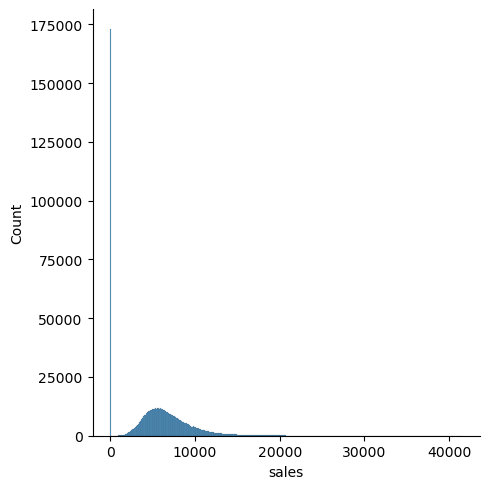

In [16]:
sns.displot(df1['sales']);

### 1.7.1. Observações:
<h4>skew</h4>
<ul>
    <li>skew muito positiva: gráfico mais deslocado para a esquerda</li>
    <li>skew muito negativa: gráfico mais deslocado para a direita</li>
</ul>
<h4>kurtosis</h4>
<ul>
    <li>kurtosis alta: maior densidade</li>
    <li>kurtosis baixa: menor densidade</li>
</ul>

## 1.7.2. Categorical Attributes

In [17]:
# quantidade de valores únicos por variável categórica
cat_attributes.apply(lambda x: x.unique().shape[0])

state_holiday      4
store_type         4
assortment         3
promo_interval     4
month_map         12
dtype: int64

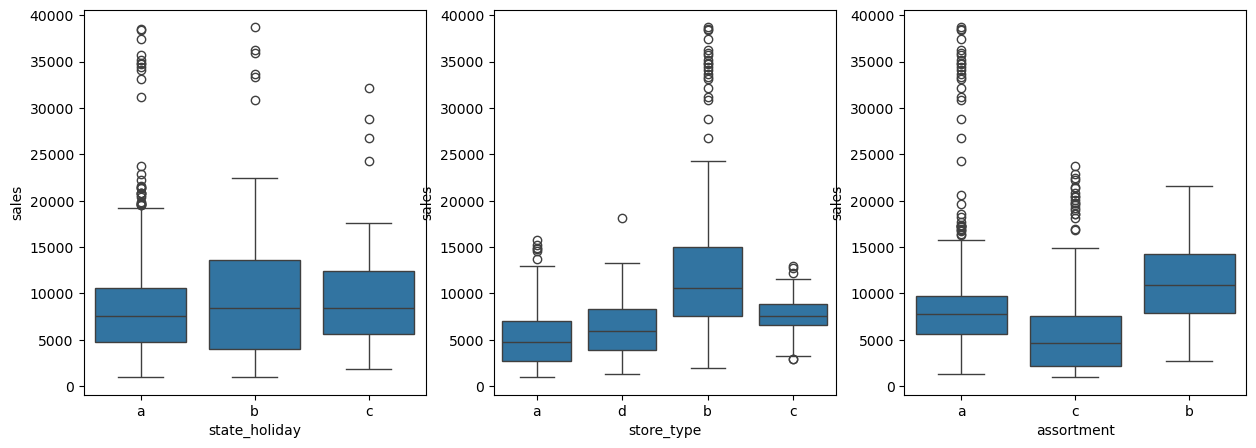

In [18]:
aux1 = df1[(df1['state_holiday'] != '0') & (df1['sales'] > 0)]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(x='state_holiday', y='sales', data=aux1, ax=ax[0]);

sns.boxplot(x='store_type', y='sales', data=aux1, ax=ax[1]);

sns.boxplot(x='assortment', y='sales', data=aux1, ax=ax[2]);

# 2.0. Passo 02 - FEATURE ENGINEERING

In [19]:
df2 = df1.copy()

## 2.1. Mapa Mental de Hipóteses

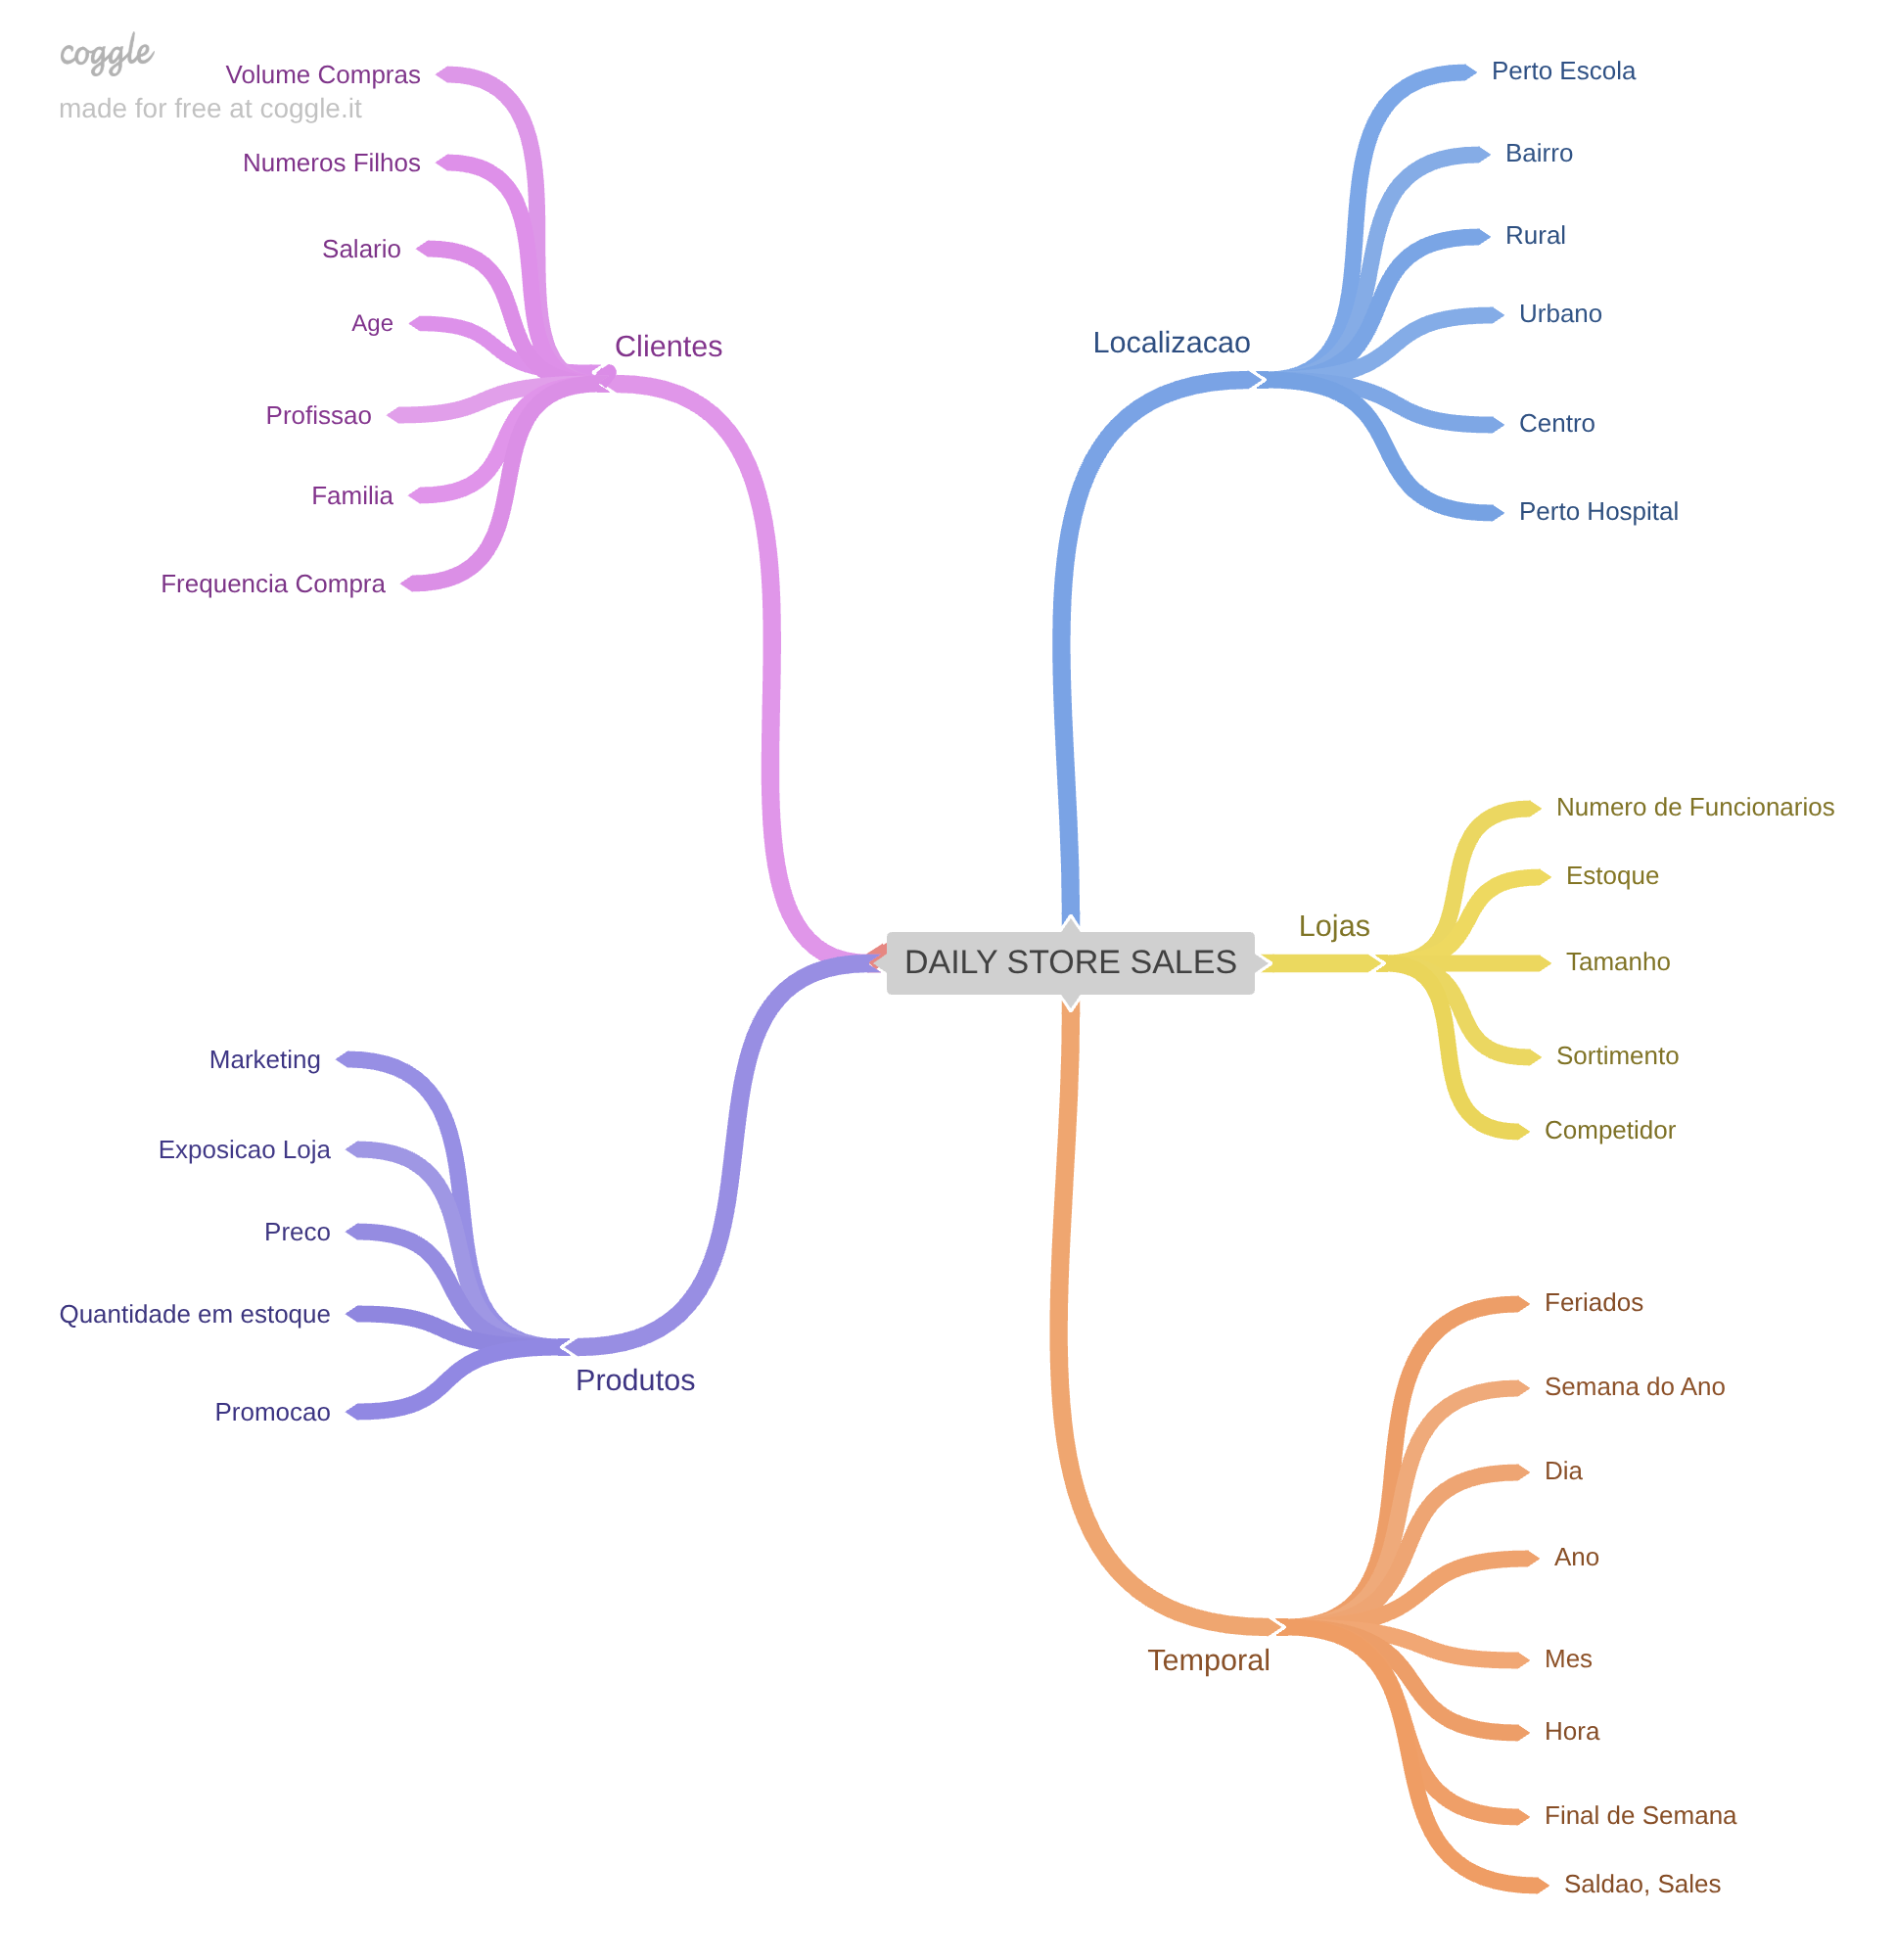

In [20]:
Image('img/MindMapHypothesis.png')

## 2.1. Criação das Hipóteses

### 2.1.1. Hipóteses Loja

**1.** Lojas com um quadro maior de funcionários deveriam vender mais.

**2.** Lojas com maior capacidade de estoque deveriam vender mais.

**3.** Lojas com maior porte deveriam vender mais.

**4.** Lojas com maior sortimentos deveriam vender mais.

**5.** Lojas com competidores mais próximos deveriam vender menos.

**6.** Lojas com competidores a mais tempo deveriam vender mais.

### 2.1.2. Hipóteses Produto

**1.** Lojas que investem mais em Marketing deveriam vender mais.

**2.** Lojas com maior exposição de produtos deveriam vender mais.

**3.** Lojas com produtos com menor preço deveriam vender mais.

**4.** Lojas com promoções mais agressivas ( descontos maiores ), deveriam vender mais.

**5.** Lojas com promoções ativas por mais tempo deveriam vender mais.

**6.** Lojas com mais dias de promoção deveriam vender mais.

**7.** Lojas com mais promoções consecutivas deveriam vender mais.

### 2.1.3. Hipóteses Tempo

**1.** Lojas abertas durante o feriado de Natal deveriam vender mais.

**2.** Lojas deveriam vender mais ao longo dos anos.

**3.** Lojas deveriam vender mais no segundo semestre do ano.

**4.** Lojas deveriam vender mais depois do dia 10 de cada mês.

**5.** Lojas deveriam vender menos aos finais de semana.

**6.** Lojas deveriam vender menos durante feriados escolares.

## 2.2. Lista Final de Hipóteses

**1.** Lojas com maior sortimentos deveriam vender mais.

**2.** Lojas com competidores mais próximos deveriam vender menos.

**3.** Lojas com competidores a mais tempo deveriam vender mais.

**4.** Lojas com promoções ativas por mais tempo deveriam vender mais.

**5.** Lojas com mais dias de promoção deveriam vender mais.

**6.** Lojas com mais promoções consecutivas deveriam vender mais.

**7.** Lojas abertas durante o feriado de Natal deveriam vender mais.

**8.** Lojas deveriam vender mais ao longo dos anos.

**9.** Lojas deveriam vender mais no segundo semestre do ano.

**10.** Lojas deveriam vender mais depois do dia 10 de cada mês.

**11.** Lojas deveriam vender menos aos finais de semana.

**12.** Lojas deveriam vender menos durante feriados escolares.

## 2.3. Feature Engineering

In [21]:
# year
df2['year'] = df2['date'].dt.year

# month
df2['month'] = df2['date'].dt.month

# day
df2['day'] = df2['date'].dt.day

# week of year
df2['week_of_year'] = df2['date'].dt.isocalendar().week

# year week
df2['year_week'] = df2['date'].dt.strftime('%Y-%W')

# competition since
df2['competition_since'] = df2.apply(lambda x: datetime.datetime( year=x['competition_open_since_year'], month=x['competition_open_since_month'], day=1), axis=1)
df2['competition_time_month'] = ( (df2['date'] - df2['competition_since']) / 30 ).apply(lambda x: x.days).astype(int)

# promo since
df2['promo_since'] = df2['promo2_since_year'].astype(str) + '-' + df2['promo2_since_week'].astype(str)
df2['promo_since'] = df2['promo_since'].apply(lambda x: datetime.datetime.strptime(x + '-1', '%Y-%W-%w') - datetime.timedelta(days=7))
df2['promo_time_week'] = ( (df2['date'] - df2['promo_since']) / 7).apply(lambda x: x.days).astype(int)

#assortment
df2['assortment'] = df2['assortment'].apply(lambda x: 'basic' if x == 'a' else 'extra' if x == 'b' else 'extended')

# state holiday
df2['state_holiday'] = df2['state_holiday'].apply(lambda x: 'public_holiday' if x == 'a' else 'easter_holiday' if x == 'b' else 'christmas' if x == 'c' else 'regular_day')


# 3.0. Passo 03 - FILTRAGEM DE VARIÁVEIS

In [22]:
df3 = df2.copy()

In [23]:
df3.head()

,store,day_of_week,date,sales,customers,open,promo,state_holiday,school_holiday,store_type,...,is_promo,year,month,day,week_of_year,year_week,competition_since,competition_time_month,promo_since,promo_time_week
0,1,5,2015-07-31,5263,555,1,1,regular_day,1,c,...,0,2015,7,31,31,2015-30,2008-09-01,84,2015-07-27,0
1,2,5,2015-07-31,6064,625,1,1,regular_day,1,a,...,1,2015,7,31,31,2015-30,2007-11-01,94,2010-03-22,279
2,3,5,2015-07-31,8314,821,1,1,regular_day,1,a,...,1,2015,7,31,31,2015-30,2006-12-01,105,2011-03-28,226
3,4,5,2015-07-31,13995,1498,1,1,regular_day,1,c,...,0,2015,7,31,31,2015-30,2009-09-01,71,2015-07-27,0
4,5,5,2015-07-31,4822,559,1,1,regular_day,1,a,...,0,2015,7,31,31,2015-30,2015-04-01,4,2015-07-27,0


## 3.1. Filtragem das Linhas

In [24]:
df3 = df3[( df3['open'] != 0 ) & ( df3['sales'] > 0 )]

## 3.2. Seleção das Colunas

In [25]:
cols_drop = ['customers', 'open', 'promo_interval', 'month_map']
df3 = df3.drop(cols_drop, axis=1)

In [26]:
df3.columns

Index(['store', 'day_of_week', 'date', 'sales', 'promo', 'state_holiday',
       'school_holiday', 'store_type', 'assortment', 'competition_distance',
       'competition_open_since_month', 'competition_open_since_year', 'promo2',
       'promo2_since_week', 'promo2_since_year', 'is_promo', 'year', 'month',
       'day', 'week_of_year', 'year_week', 'competition_since',
       'competition_time_month', 'promo_since', 'promo_time_week'],
      dtype='object')

# 4.0. Passo 04 - ANÁLISE EXPLORATÓRIA DE DADOS

In [27]:
df4 = df3.copy()

## 4.1. Análise Univariada

### 4.1.1. Variável Resposta

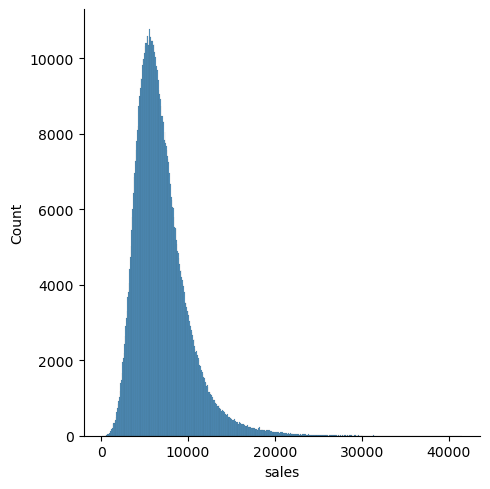

In [28]:
sns.displot( df4['sales'] );

### 4.1.2. Variáveis Numéricas

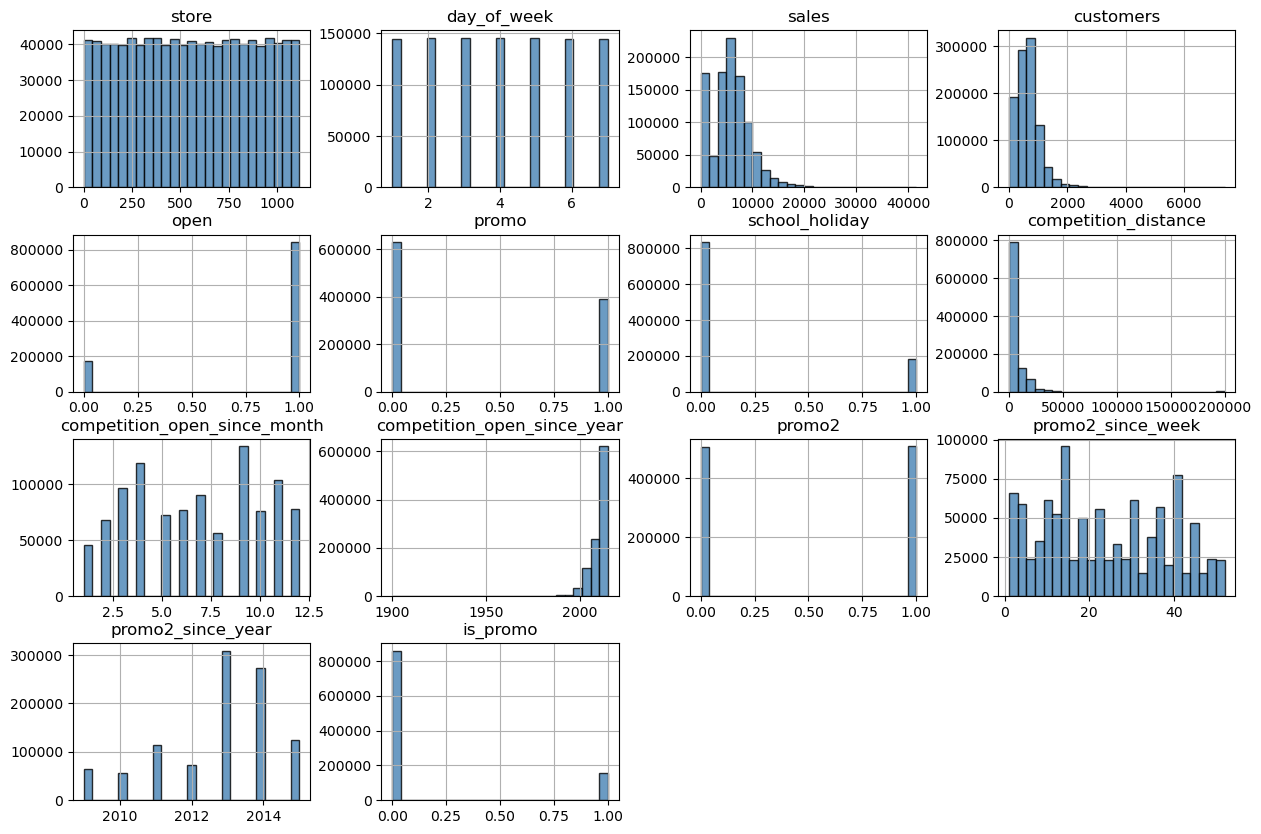

In [29]:
num_attributes.hist(bins=25, figsize=(15, 10), color='steelblue', edgecolor='black', alpha=0.8);

### 4.1.3. Variáveis Categóricas

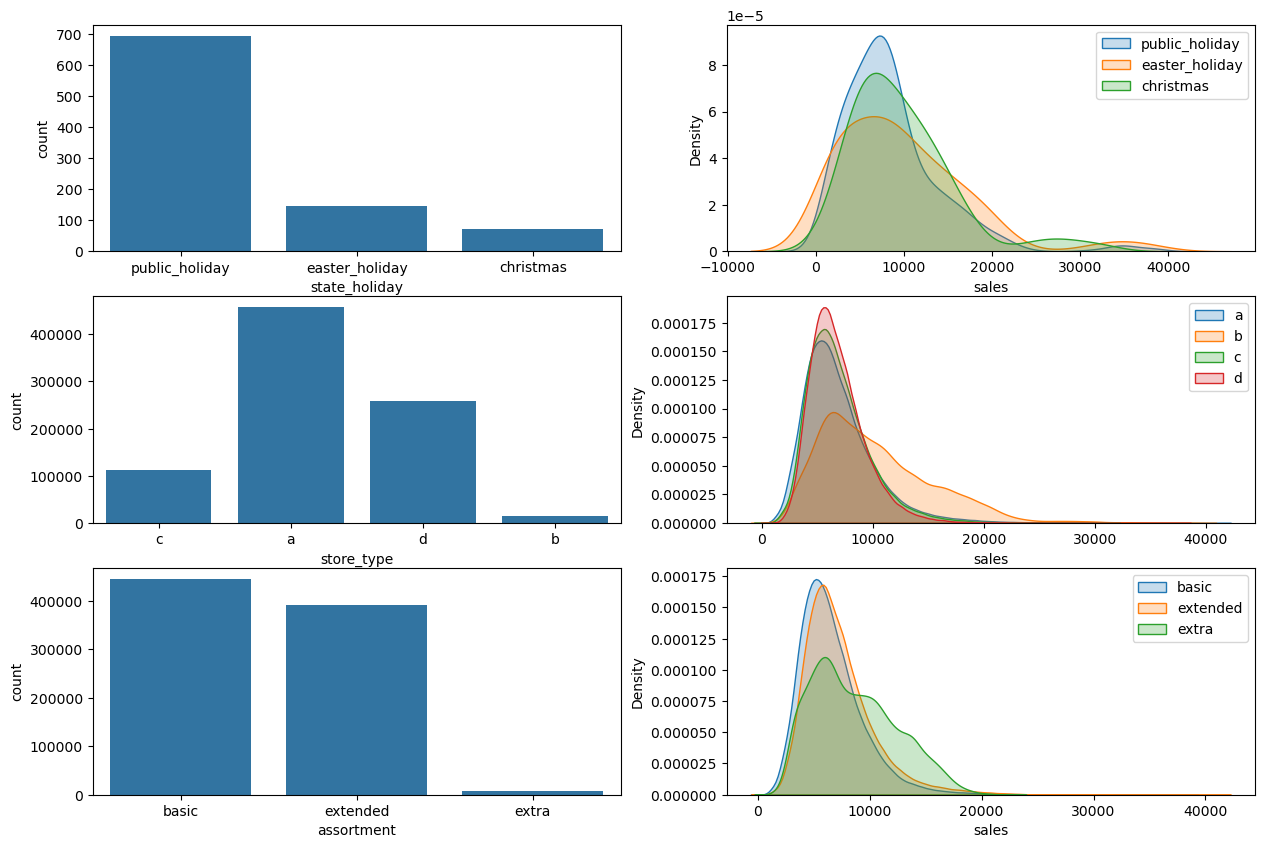

In [30]:
# state_holiday
fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(nrows=3, ncols=2, figsize=(15, 10))

filtro = df4[df4['state_holiday'] != 'regular_day']
sns.countplot( x='state_holiday', data=filtro, ax=ax1);

sns.kdeplot( df4[df4['state_holiday'] == 'public_holiday']['sales'], fill=True, ax=ax2);
sns.kdeplot( df4[df4['state_holiday'] == 'easter_holiday']['sales'], fill=True, ax=ax2);
sns.kdeplot( df4[df4['state_holiday'] == 'christmas']['sales'], fill=True, ax=ax2);
ax2.legend(['public_holiday', 'easter_holiday', 'christmas']);

# store_type
sns.countplot( x='store_type', data=df4, ax=ax3);

sns.kdeplot( df4[df4['store_type'] == 'a']['sales'], fill=True, ax=ax4);
sns.kdeplot( df4[df4['store_type'] == 'b']['sales'], fill=True, ax=ax4);
sns.kdeplot( df4[df4['store_type'] == 'c']['sales'], fill=True, ax=ax4);
sns.kdeplot( df4[df4['store_type'] == 'd']['sales'], fill=True, ax=ax4);
ax4.legend(['a', 'b', 'c', 'd']);

# assortment
sns.countplot( x='assortment', data=df4, ax=ax5);

sns.kdeplot( df4[df4['assortment'] == 'basic']['sales'], fill=True, ax=ax6);
sns.kdeplot( df4[df4['assortment'] == 'extended']['sales'], fill=True, ax=ax6);
sns.kdeplot( df4[df4['assortment'] == 'extra']['sales'], fill=True, ax=ax6);
ax6.legend(['basic', 'extended', 'extra']);


## 4.2. Análise Bivariada

### **H1.** Lojas com maior sortimentos deveriam vender mais.
#### **FALSA:** Lojas com MAIOR SORTIMENTO vendem MENOS.

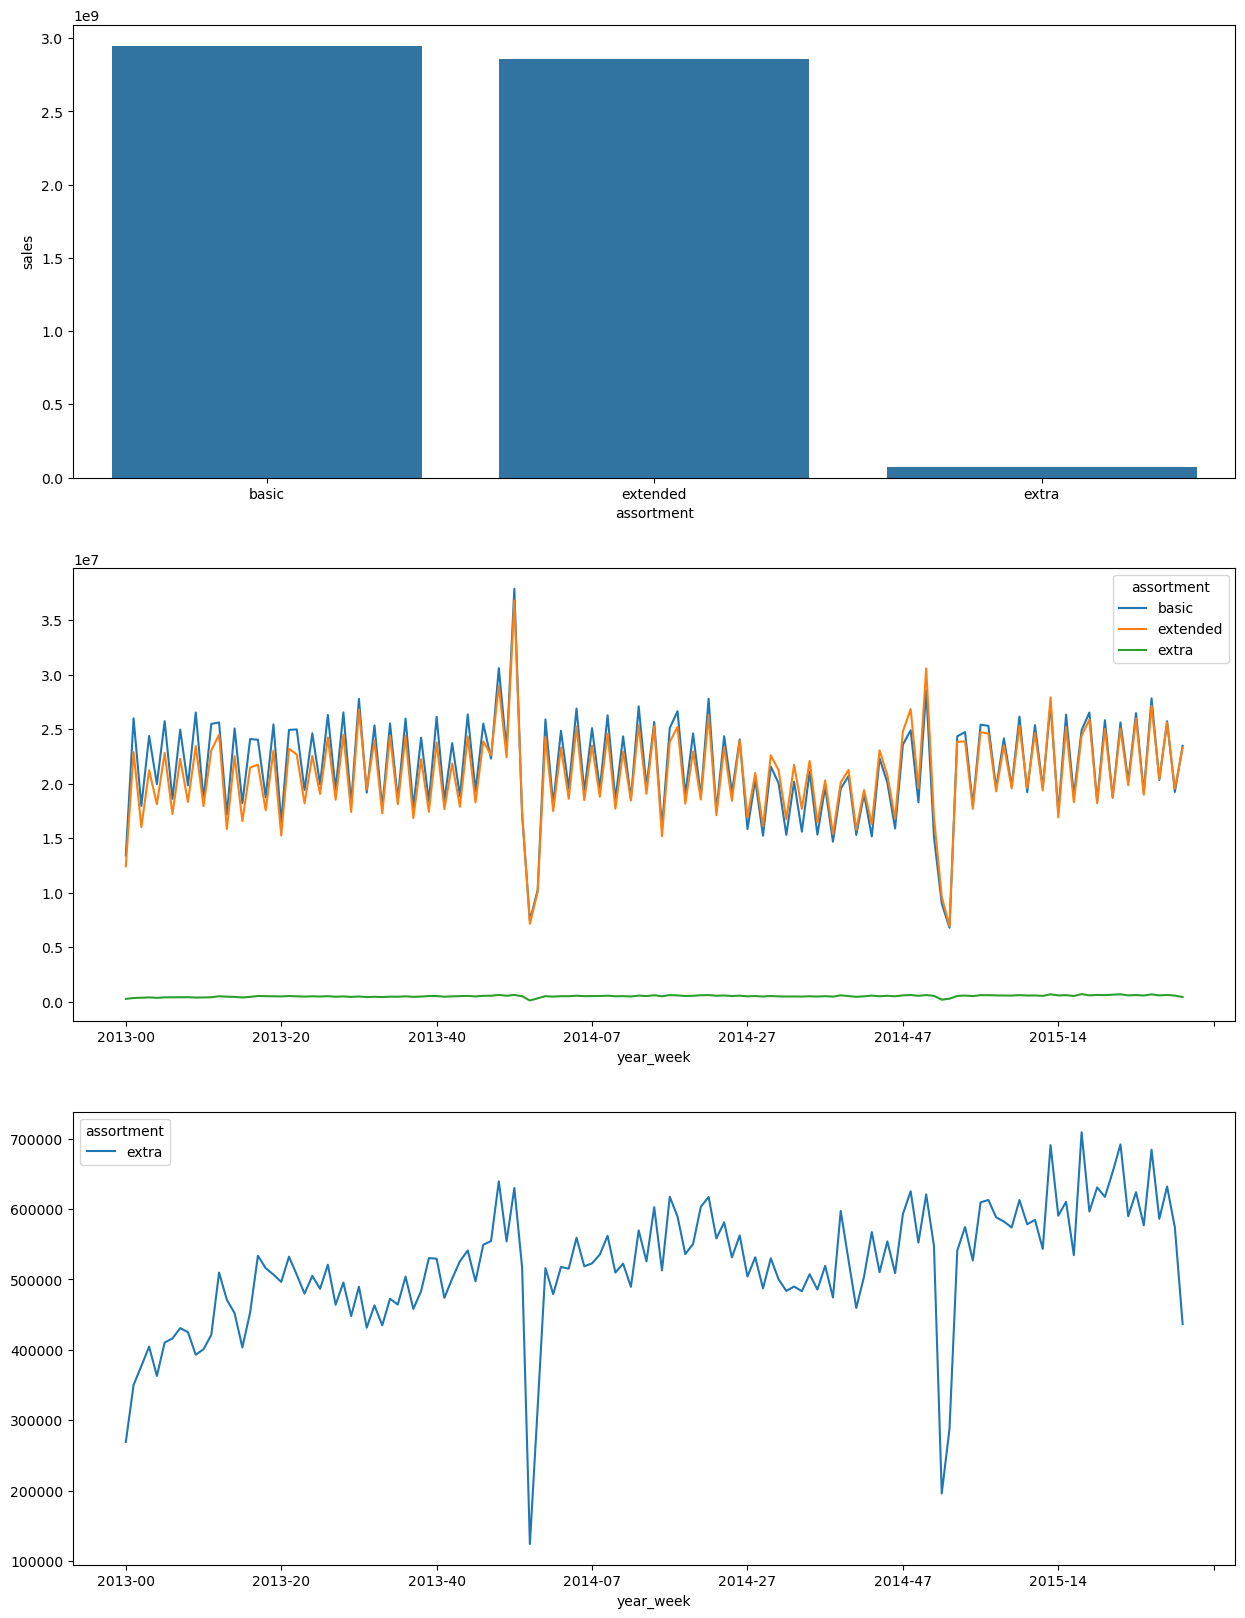

In [31]:
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(15, 20))

aux1 = df4[['assortment', 'sales']].groupby('assortment').sum().reset_index()
sns.barplot(x='assortment', y='sales', data=aux1, ax=ax[0]);

aux2 = df4[['year_week', 'assortment', 'sales']].groupby(['year_week', 'assortment']).sum().reset_index()
aux2.pivot(index='year_week', columns='assortment', values='sales').plot(ax=ax[1]);

aux3 = aux2[aux2['assortment'] == 'extra']
aux3.pivot(index='year_week', columns='assortment', values='sales').plot(ax=ax[2]);

### **H2.** Lojas com competidores mais próximos deveriam vender menos.
#### **FALSA:** Lojas com COMPETIDORES MAIS PRÓXIMOS vendem MAIS.

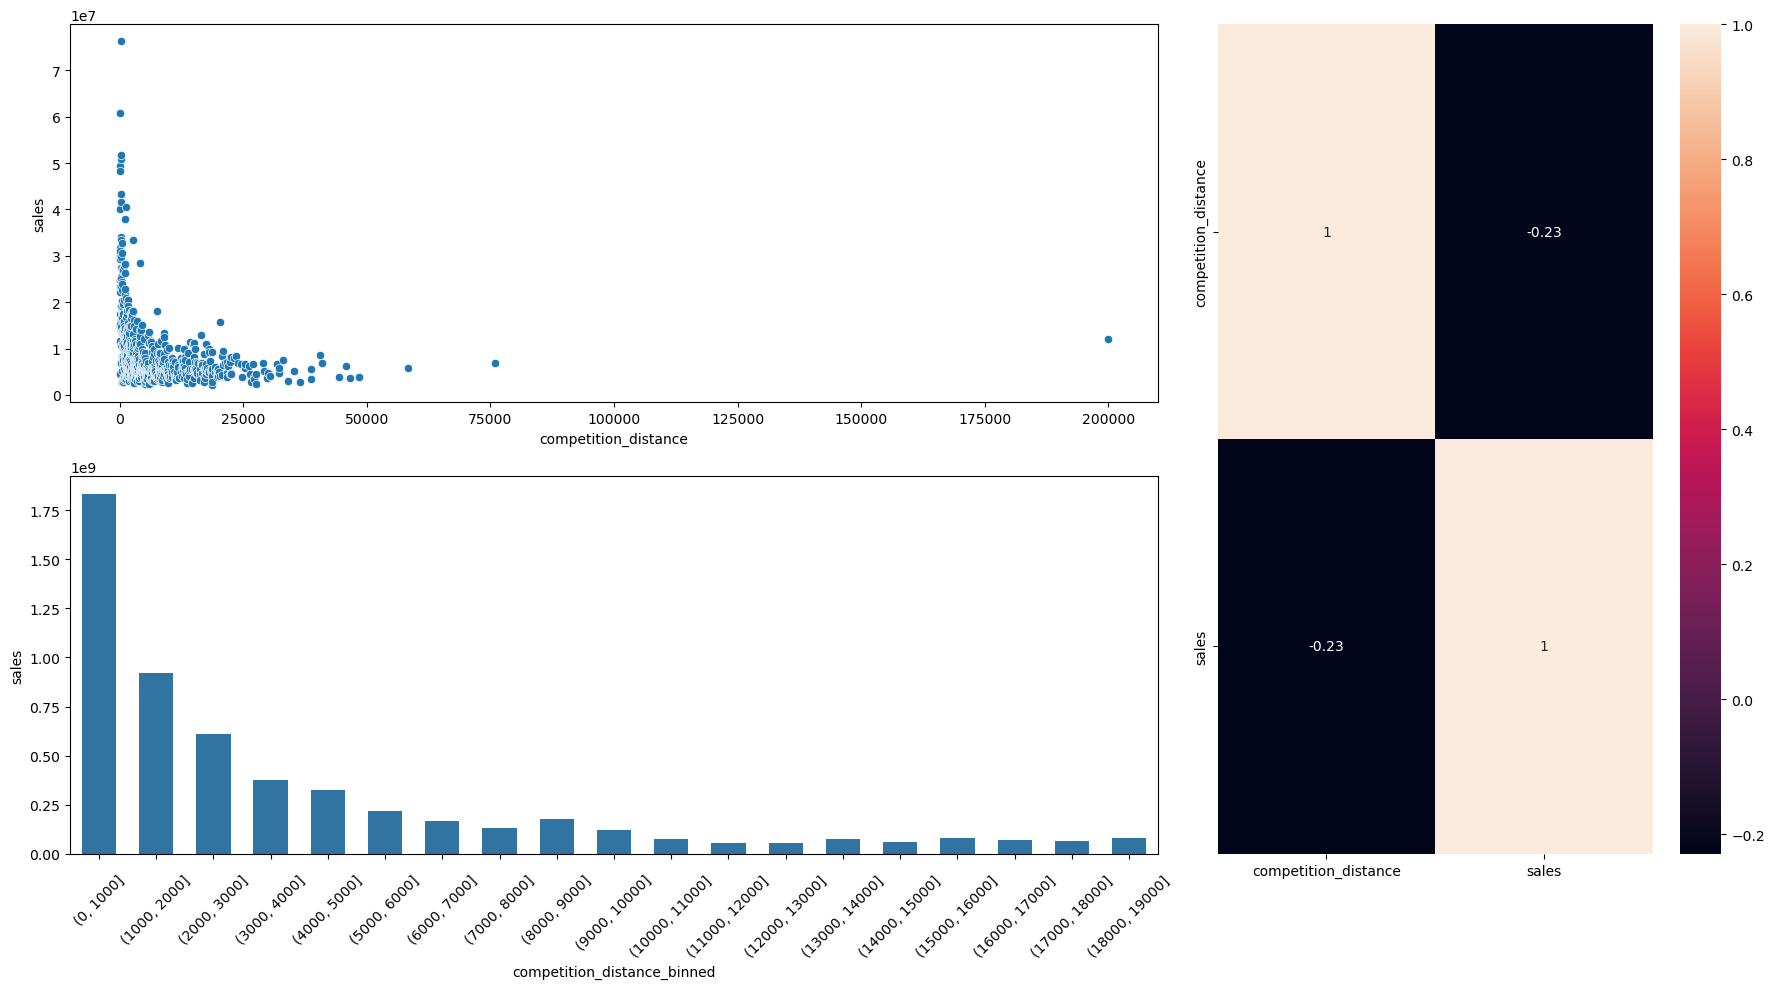

In [32]:
fig = plt.figure(figsize=(18, 10))

gs = fig.add_gridspec(2, 2, width_ratios=[2, 1])

# Primeiro gráfico, superior esquerdo
ax1 = fig.add_subplot(gs[0, 0])

# Segundo gráfico, inferior esquerdo
ax2 = fig.add_subplot(gs[1, 0])

# Terceiro gráfico, ocupando as duas linhas da direita
ax3 = fig.add_subplot(gs[:, 1])

aux1 = df4[['competition_distance', 'sales']].groupby('competition_distance').sum().reset_index()

# scatterplot
sns.scatterplot(x='competition_distance', y='sales', data=aux1, ax=ax1)

# barplot
bins = list(np.arange(0, 20000, 1000))
aux1['competition_distance_binned'] = pd.cut(aux1['competition_distance'], bins=bins)

aux2 = aux1[['competition_distance_binned', 'sales']].groupby(
    'competition_distance_binned', observed=False
).sum().reset_index()

sns.barplot(
    x='competition_distance_binned',
    y='sales',
    data=aux2,
    width=0.6,
    ax=ax2
)

ax2.tick_params(axis='x', labelrotation=45, pad=10)

# heatmap
sns.heatmap(
    aux1.select_dtypes(include='number').corr(method='pearson'),
    annot=True,
    ax=ax3
)

plt.tight_layout()

### **H3.** Lojas com competidores a mais tempo deveriam vender mais.
#### **FALSA:** Lojas com COMPETIDORES A MAIS TEMPO vendem MENOS.

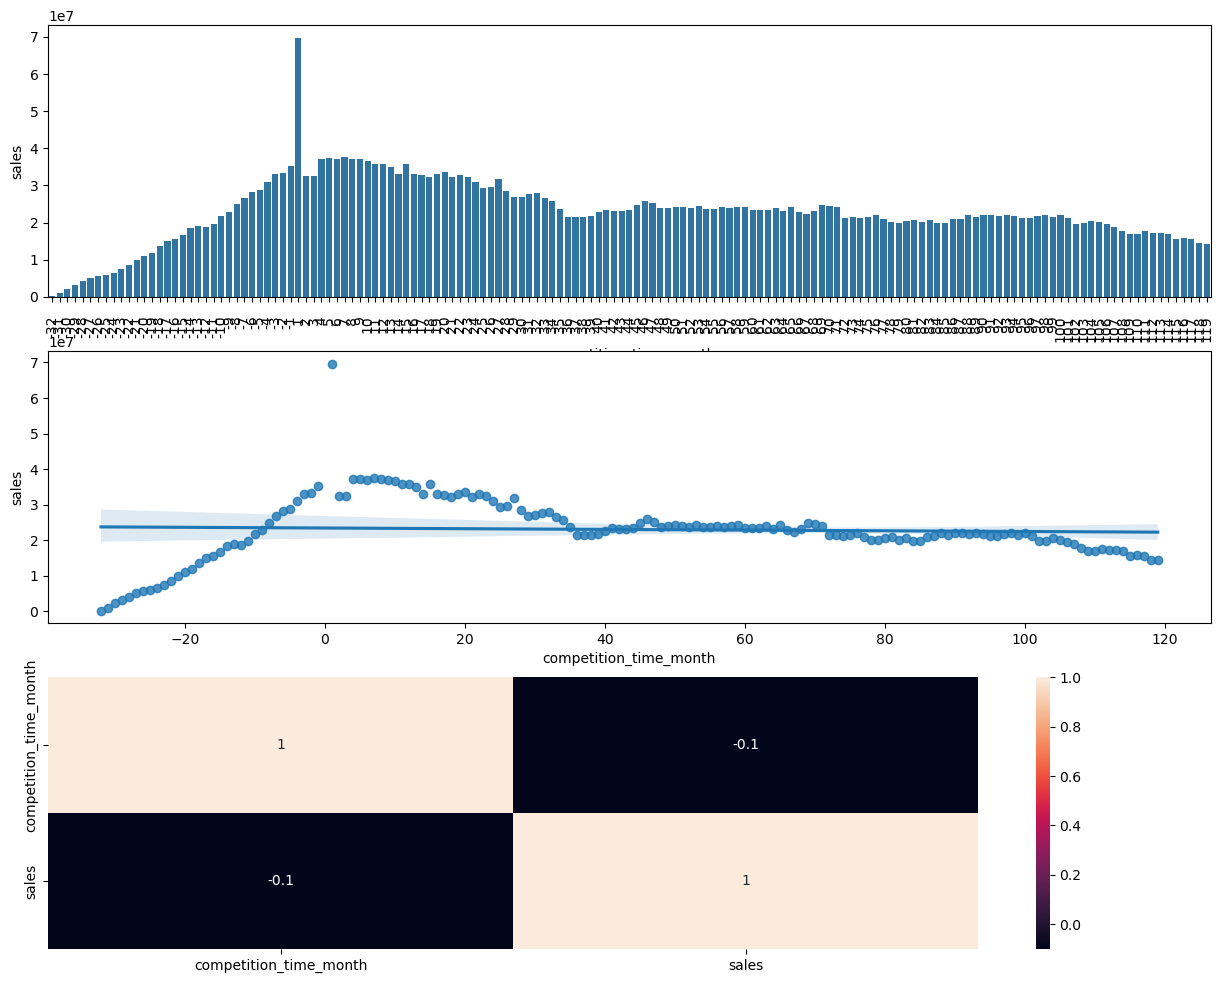

In [33]:
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(15, 12))

aux1 = df4[['competition_time_month', 'sales']].groupby('competition_time_month').sum().reset_index()
aux2 = aux1[(aux1['competition_time_month'] < 120) & (aux1['competition_time_month'] != 0)]

# barplot
sns.barplot(x='competition_time_month', y='sales', data=aux2, ax=ax[0]);
ax[0].tick_params(axis='x', labelrotation=90, pad=10)

# regplot
sns.regplot(x='competition_time_month', y='sales', data=aux2, ax=ax[1]);

# heatmap
sns.heatmap(aux1.corr(method='pearson'), annot=True, ax=ax[2]);

### **H4.** Lojas com promoções ativas por mais tempo deveriam vender mais.
#### **FALSA:** Lojas com PROMOÇÕES ATIVAS POR MAIS TEMPO vendem MENOS.

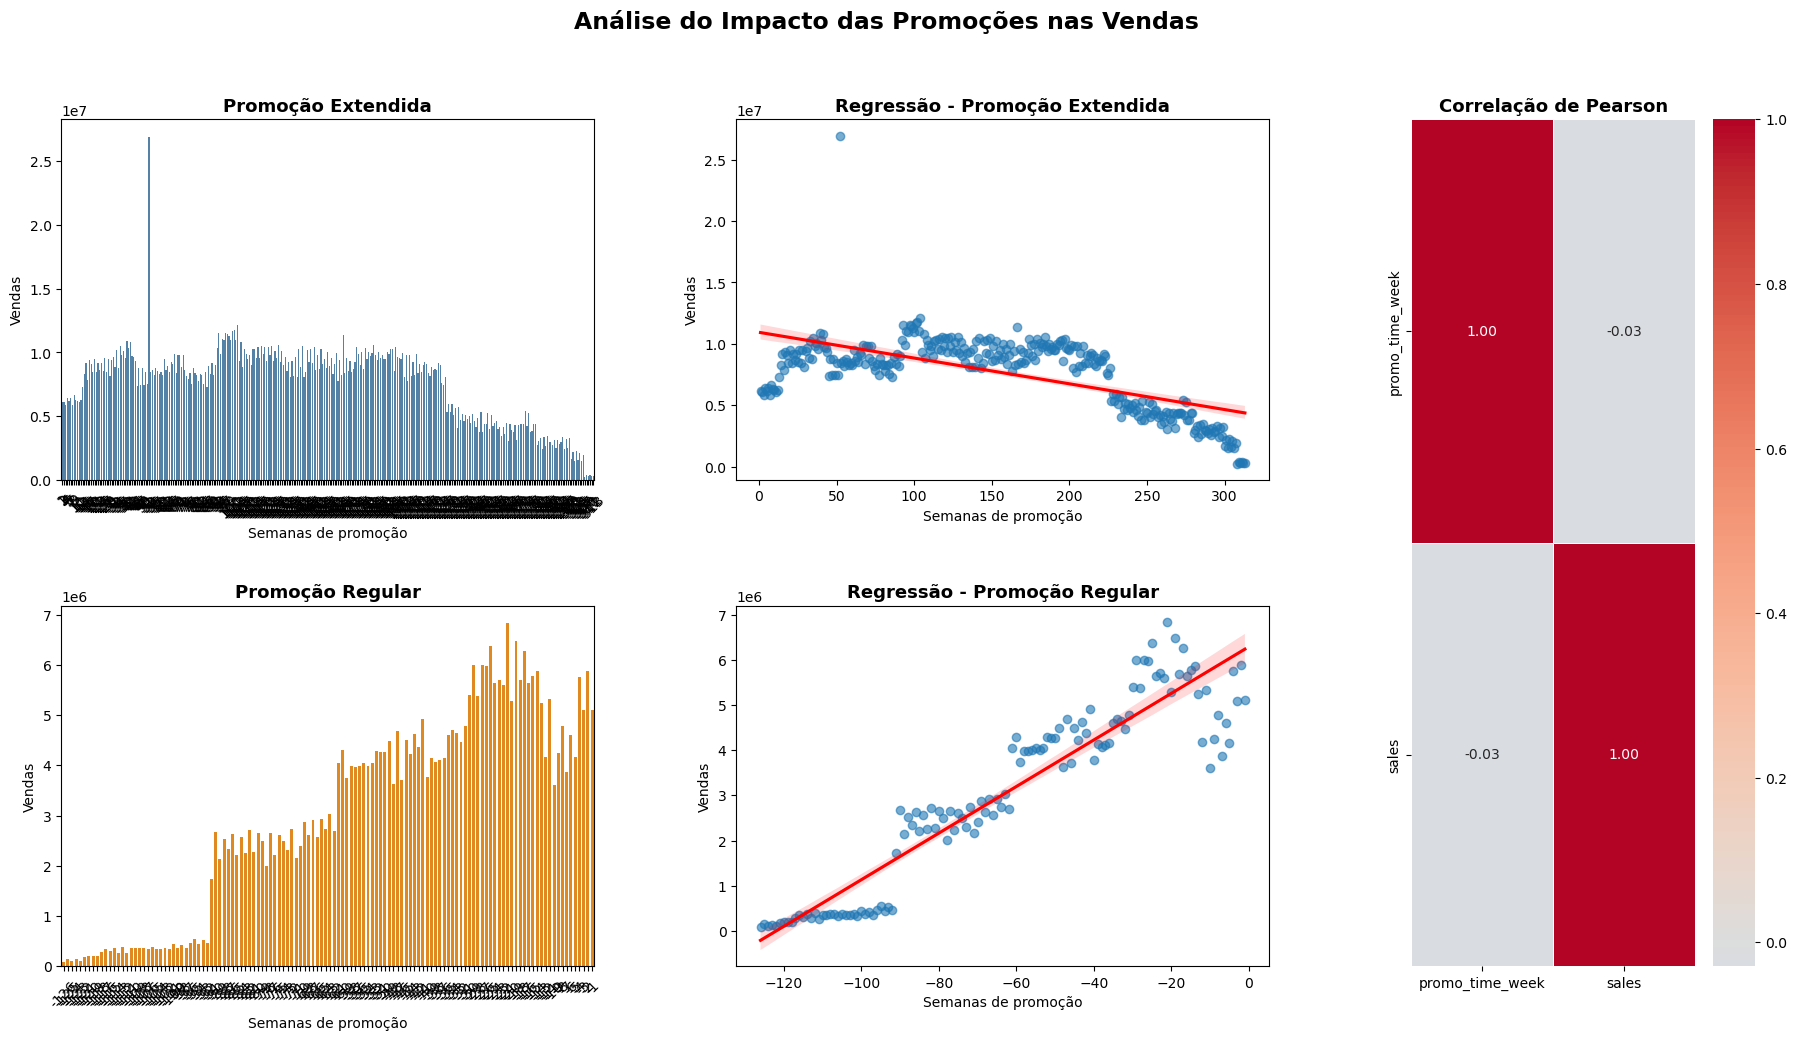

In [34]:
fig = plt.figure(figsize=(22, 11))

gs = fig.add_gridspec(
    2, 3,
    width_ratios=[1.5, 1.5, 1],
    hspace=0.35,
    wspace=0.3
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])
ax5 = fig.add_subplot(gs[:, 2])

aux1 = df4[['promo_time_week', 'sales']].groupby(
    'promo_time_week'
).sum().reset_index()

# Promoção extendida
aux2 = aux1[aux1['promo_time_week'] > 0]

sns.barplot(
    x='promo_time_week',
    y='sales',
    data=aux2,
    ax=ax1,
    color='steelblue',
    width=0.7
)

ax1.set_title('Promoção Extendida', fontsize=13, fontweight='bold')
ax1.set_xlabel('Semanas de promoção')
ax1.set_ylabel('Vendas')
ax1.tick_params(axis='x', rotation=45, pad=5)

# Regressão - promoção estendida
sns.regplot(
    x='promo_time_week',
    y='sales',
    data=aux2,
    ax=ax2,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

ax2.set_title('Regressão - Promoção Extendida', fontsize=13, fontweight='bold')
ax2.set_xlabel('Semanas de promoção')
ax2.set_ylabel('Vendas')

# Promoção regular
aux3 = aux1[aux1['promo_time_week'] < 0]

sns.barplot(
    x='promo_time_week',
    y='sales',
    data=aux3,
    ax=ax3,
    color='darkorange',
    width=0.7
)

ax3.set_title('Promoção Regular', fontsize=13, fontweight='bold')
ax3.set_xlabel('Semanas de promoção')
ax3.set_ylabel('Vendas')
ax3.tick_params(axis='x', rotation=45, pad=5)

# Regressão - promoção regular
sns.regplot(
    x='promo_time_week',
    y='sales',
    data=aux3,
    ax=ax4,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

ax4.set_title('Regressão - Promoção Regular', fontsize=13, fontweight='bold')
ax4.set_xlabel('Semanas de promoção')
ax4.set_ylabel('Vendas')

# Heatmap
sns.heatmap(
    aux1.corr(method='pearson'),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    ax=ax5
)

ax5.set_title('Correlação de Pearson', fontsize=13, fontweight='bold')

fig.suptitle(
    'Análise do Impacto das Promoções nas Vendas',
    fontsize=17,
    fontweight='bold'
)

plt.show();

### <s> **H5.** Lojas com mais dias de promoção deveriam vender mais. </s>

### **H6.** Lojas com mais promoções consecutivas deveriam vender mais.
#### **FALSA:** Lojas com MAIS PROMOÇÕES CONSECUTIVAS vendem MENOS.

In [35]:
df4[['promo', 'promo2', 'sales']].groupby(['promo', 'promo2']).sum().reset_index().sort_values(by='sales', ascending=False)

,promo,promo2,sales
2,1,0,1628930532
0,0,0,1482612096
3,1,1,1472275754
1,0,1,1289362241


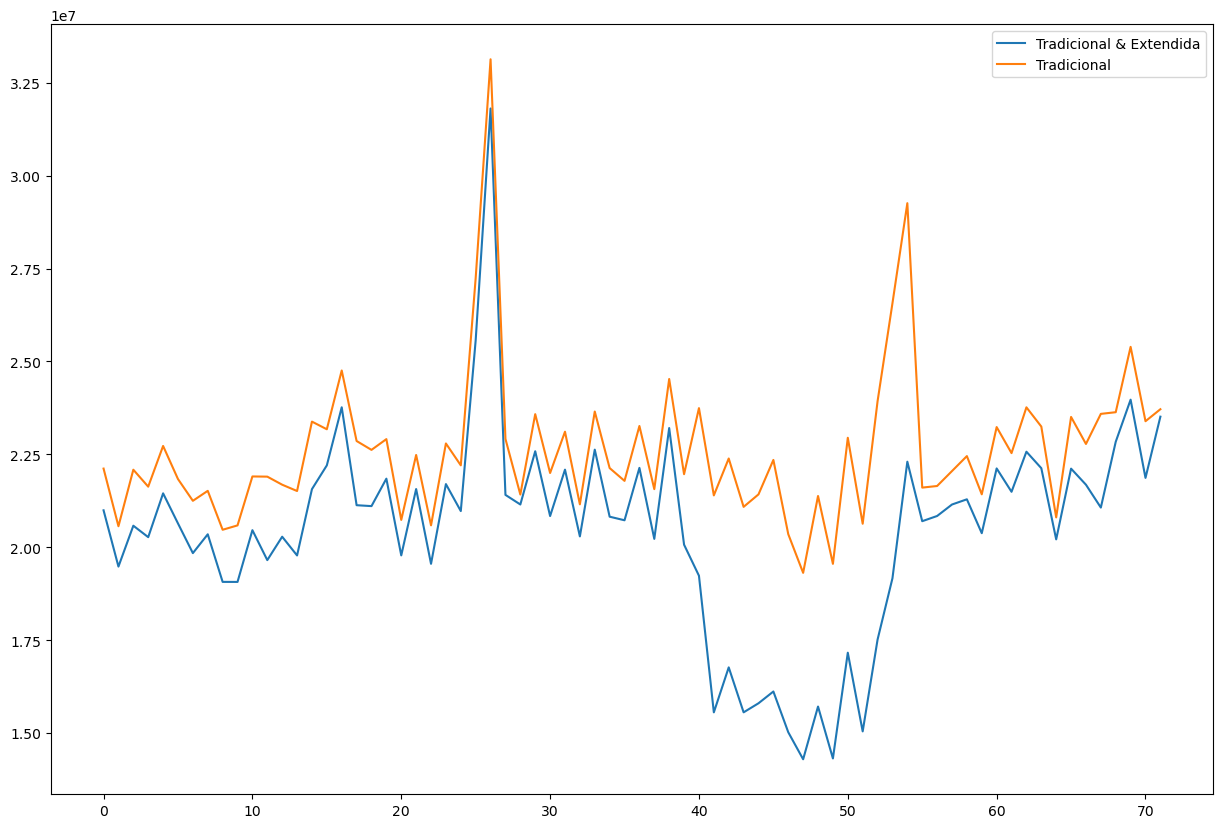

In [36]:
fig, ax = plt.subplots(figsize=(15, 10))

promo_consecutiva = (df4['promo'] == 1) & (df4['promo2'] == 1)
aux1 = df4[promo_consecutiva][['year_week', 'sales']].groupby('year_week').sum().reset_index()
aux1.plot(ax=ax);

promo_extendida = (df4['promo'] == 1) & (df4['promo2'] == 0)
aux2 = df4[promo_extendida][['year_week', 'sales']].groupby('year_week').sum().reset_index()
aux2.plot(ax=ax);

ax.legend(['Tradicional & Extendida', 'Tradicional']);

### **H7.** Lojas abertas durante o feriado de Natal deveriam vender mais.
#### **FALSA:** Lojas ABERTAS DURANTE O FERIADO DE NATAL vendem MENOS.

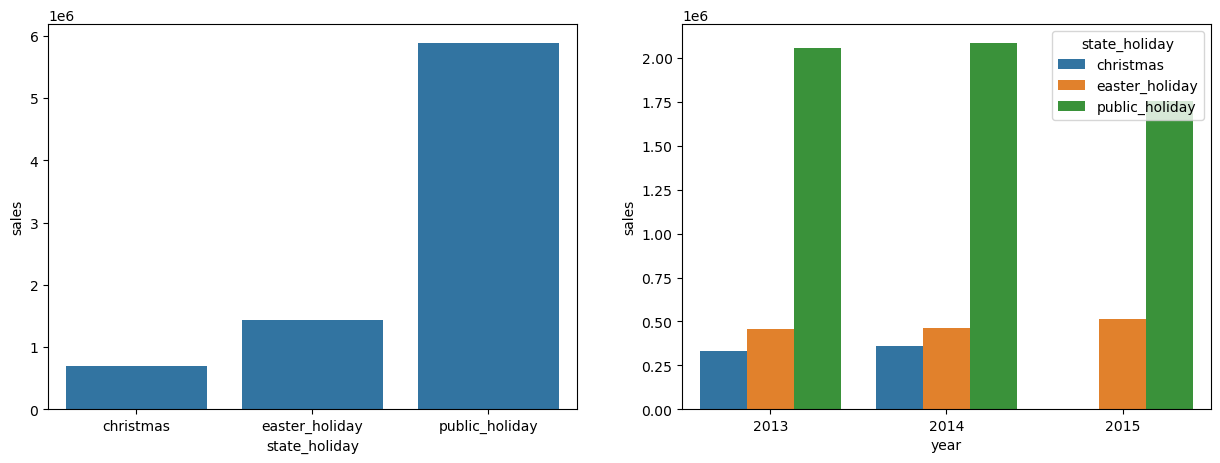

In [37]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

aux = df4[df4['state_holiday'] != 'regular_day']
aux1 = aux[['state_holiday', 'sales']].groupby('state_holiday').sum().reset_index()
sns.barplot(x='state_holiday', y='sales', data=aux1, ax=ax[0]);

aux2 = aux[['year', 'state_holiday', 'sales']].groupby(['year', 'state_holiday']).sum().reset_index()
sns.barplot(x='year', y='sales', hue='state_holiday', data=aux2, ax=ax[1]);

### **H8.** Lojas deveriam vender mais ao longo dos anos.
#### **FALSA:** Lojas VENDEM MENOS AO LONGO DOS ANOS.

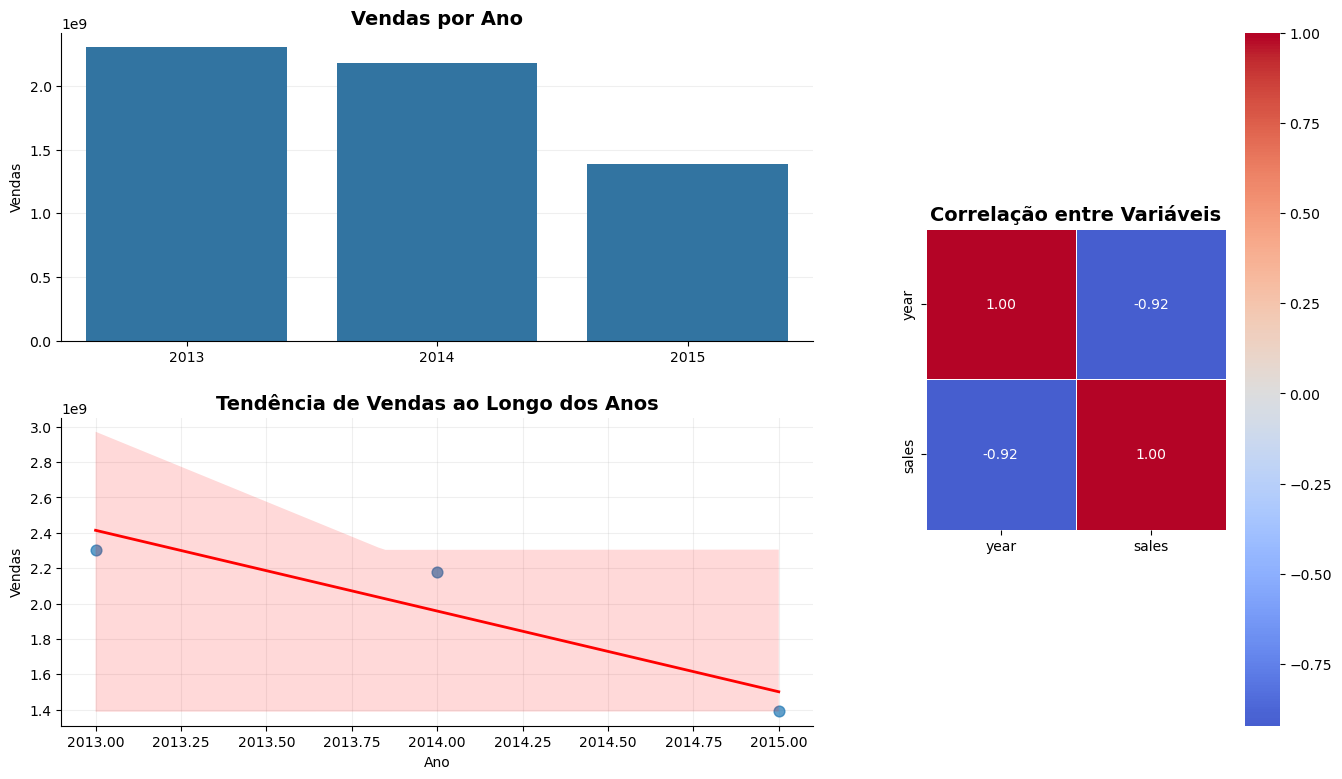

In [38]:
fig = plt.figure(figsize=(16, 9))

gs = fig.add_gridspec(
    2, 2,
    width_ratios=[2, 1],
    hspace=0.25,
    wspace=0.20
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[:, 1])

aux = df4[['year', 'sales']].groupby('year').sum().reset_index()

# Gráfico de barras
sns.barplot(
    x='year',
    y='sales',
    data=aux,
    ax=ax1
)

ax1.set_title('Vendas por Ano', fontsize=14, weight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Vendas')
ax1.grid(axis='y', alpha=0.2)
ax1.set_axisbelow(True)

# Gráfico de regressão
sns.regplot(
    x='year',
    y='sales',
    data=aux,
    ax=ax2,
    scatter_kws={'s': 60, 'alpha': 0.7},
    line_kws={'color': 'red', 'linewidth': 2}
)

ax2.set_title('Tendência de Vendas ao Longo dos Anos', fontsize=14, weight='bold')
ax2.set_xlabel('Ano')
ax2.set_ylabel('Vendas')
ax2.grid(alpha=0.2)
ax2.set_axisbelow(True)

# Heatmap
sns.heatmap(
    aux.corr(method='pearson'),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    ax=ax3,
    square=True
)

ax3.set_title('Correlação entre Variáveis', fontsize=14, weight='bold')

# Removendo bordas superiores e laterais
for ax in [ax1, ax2]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Ajustes finais
fig.patch.set_facecolor('white')

plt.show()

### **H9.** Lojas deveriam vender mais no segundo semestre do ano.
#### **FALSA:** Lojas VENDEM MENOS NO SEGUNDO SEMESTRE DO ANO.

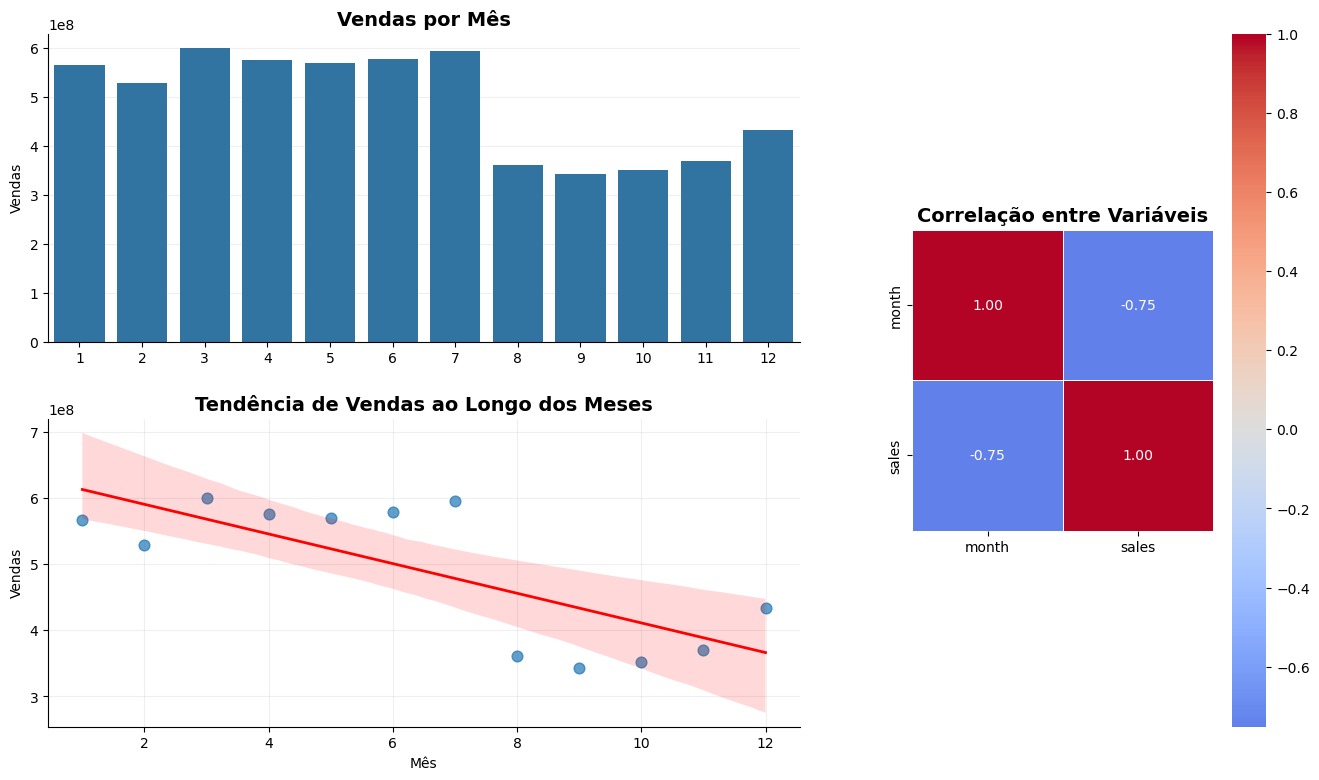

In [39]:
fig = plt.figure(figsize=(16, 9))

gs = fig.add_gridspec(
    2, 2,
    width_ratios=[2, 1],
    hspace=0.25,
    wspace=0.20
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[:, 1])

aux = df4[['month', 'sales']].groupby('month').sum().reset_index()

# Gráfico de barras
sns.barplot(
    x='month',
    y='sales',
    data=aux,
    ax=ax1
)

ax1.set_title('Vendas por Mês', fontsize=14, weight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Vendas')
ax1.grid(axis='y', alpha=0.2)
ax1.set_axisbelow(True)

# Gráfico de regressão
sns.regplot(
    x='month',
    y='sales',
    data=aux,
    ax=ax2,
    scatter_kws={'s': 60, 'alpha': 0.7},
    line_kws={'color': 'red', 'linewidth': 2}
)

ax2.set_title('Tendência de Vendas ao Longo dos Meses', fontsize=14, weight='bold')
ax2.set_xlabel('Mês')
ax2.set_ylabel('Vendas')
ax2.grid(alpha=0.2)
ax2.set_axisbelow(True)

# Heatmap
sns.heatmap(
    aux.corr(method='pearson'),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    ax=ax3,
    square=True
)

ax3.set_title('Correlação entre Variáveis', fontsize=14, weight='bold')

# Removendo bordas superiores e laterais
for ax in [ax1, ax2]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Ajustes finais
fig.patch.set_facecolor('white')

plt.show()

### **H10.** Lojas deveriam vender mais depois do dia 10 de cada mês.
#### **FALSA:** Lojas VENDEM MENOS DEPOIS DO DIA 10 DE CADA MÊS.

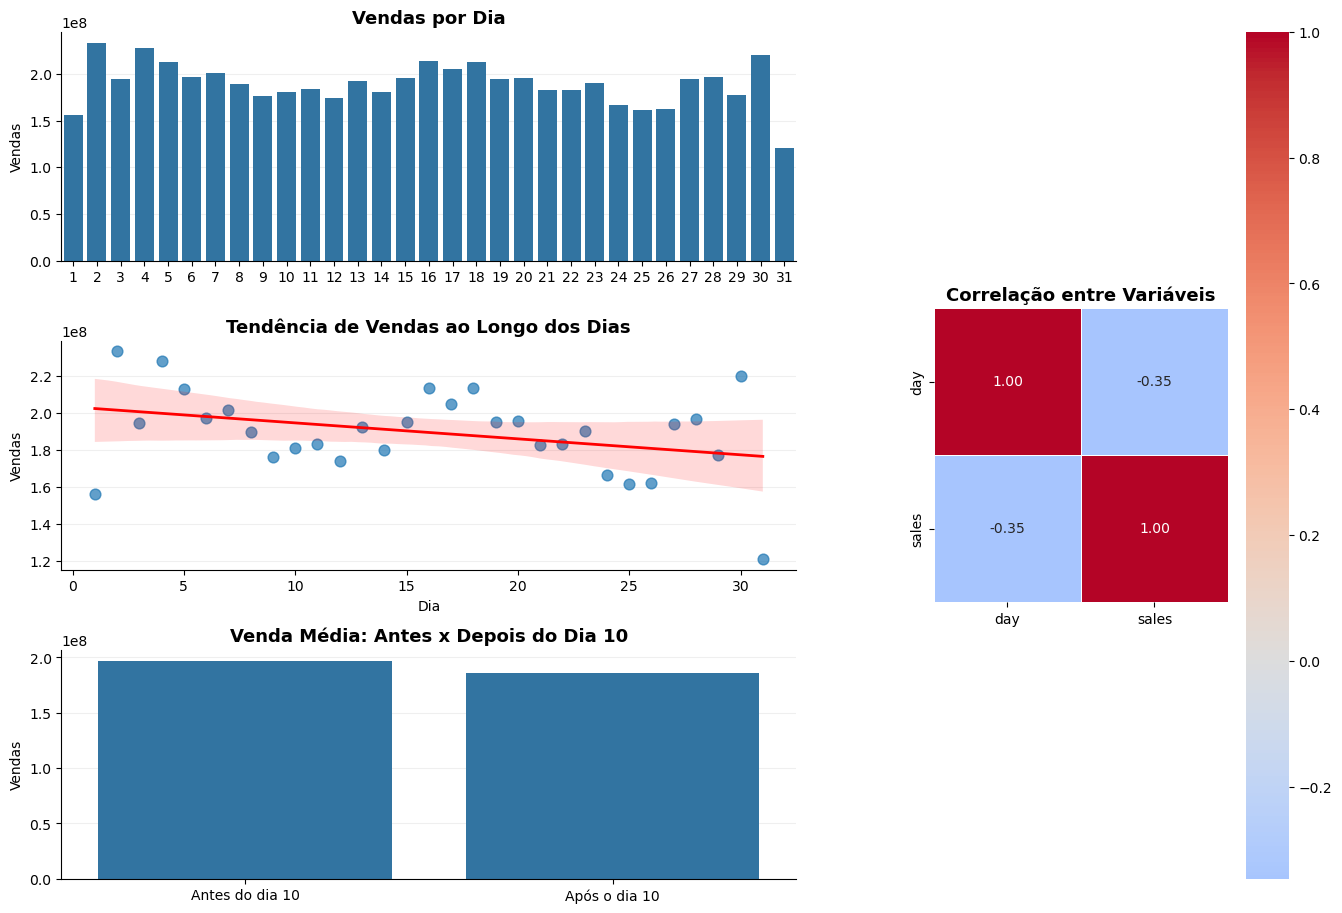

In [40]:
fig = plt.figure(figsize=(16, 11))

gs = fig.add_gridspec(
    3, 2,
    width_ratios=[2, 1],
    height_ratios=[1, 1, 1],
    hspace=0.35,
    wspace=0.25
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[:, 1])

# Preparação dos dados
aux1 = df4[['day', 'sales']].groupby('day').sum().reset_index()

# 1. Gráfico de barras
sns.barplot(
    x='day',
    y='sales',
    data=aux1,
    ax=ax1
)

ax1.set_title('Vendas por Dia', fontsize=13, weight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Vendas')
ax1.grid(axis='y', alpha=0.2)
ax1.set_axisbelow(True)

# 2. Gráfico de regressão
sns.regplot(
    x='day',
    y='sales',
    data=aux1,
    ax=ax2,
    scatter_kws={'s': 60, 'alpha': 0.7},
    line_kws={'color': 'red', 'linewidth': 2}
)

ax2.set_title('Tendência de Vendas ao Longo dos Dias', fontsize=13, weight='bold')
ax2.set_xlabel('Dia')
ax2.set_ylabel('Vendas')
ax2.grid(axis='y', alpha=0.2)
ax2.set_axisbelow(True)

# 3. Vendas antes e depois do dia 10
aux1['before_after'] = aux1['day'].apply(
    lambda x: 'Antes do dia 10' if x <= 10 else 'Após o dia 10'
)

aux2 = aux1.groupby('before_after')['sales'].mean().reset_index()

sns.barplot(
    x='before_after',
    y='sales',
    data=aux2,
    ax=ax3
)

ax3.set_title('Venda Média: Antes x Depois do Dia 10', fontsize=13, weight='bold')
ax3.set_xlabel('')
ax3.set_ylabel('Vendas')
ax3.grid(axis='y', alpha=0.2)
ax3.set_axisbelow(True)

# 4. Heatmap
sns.heatmap(
    aux1[['day', 'sales']].corr(method='pearson'),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    square=True,
    ax=ax4
)

ax4.set_title('Correlação entre Variáveis', fontsize=13, weight='bold')

# Removendo bordas desnecessárias
for ax in [ax1, ax2, ax3]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.patch.set_facecolor('white')

plt.show()

### **H11.** Lojas deveriam vender menos aos finais de semana.
#### **VERDADEIRO:** Lojas VENDEM MENOS AOS FINAIS DE SEMANA.

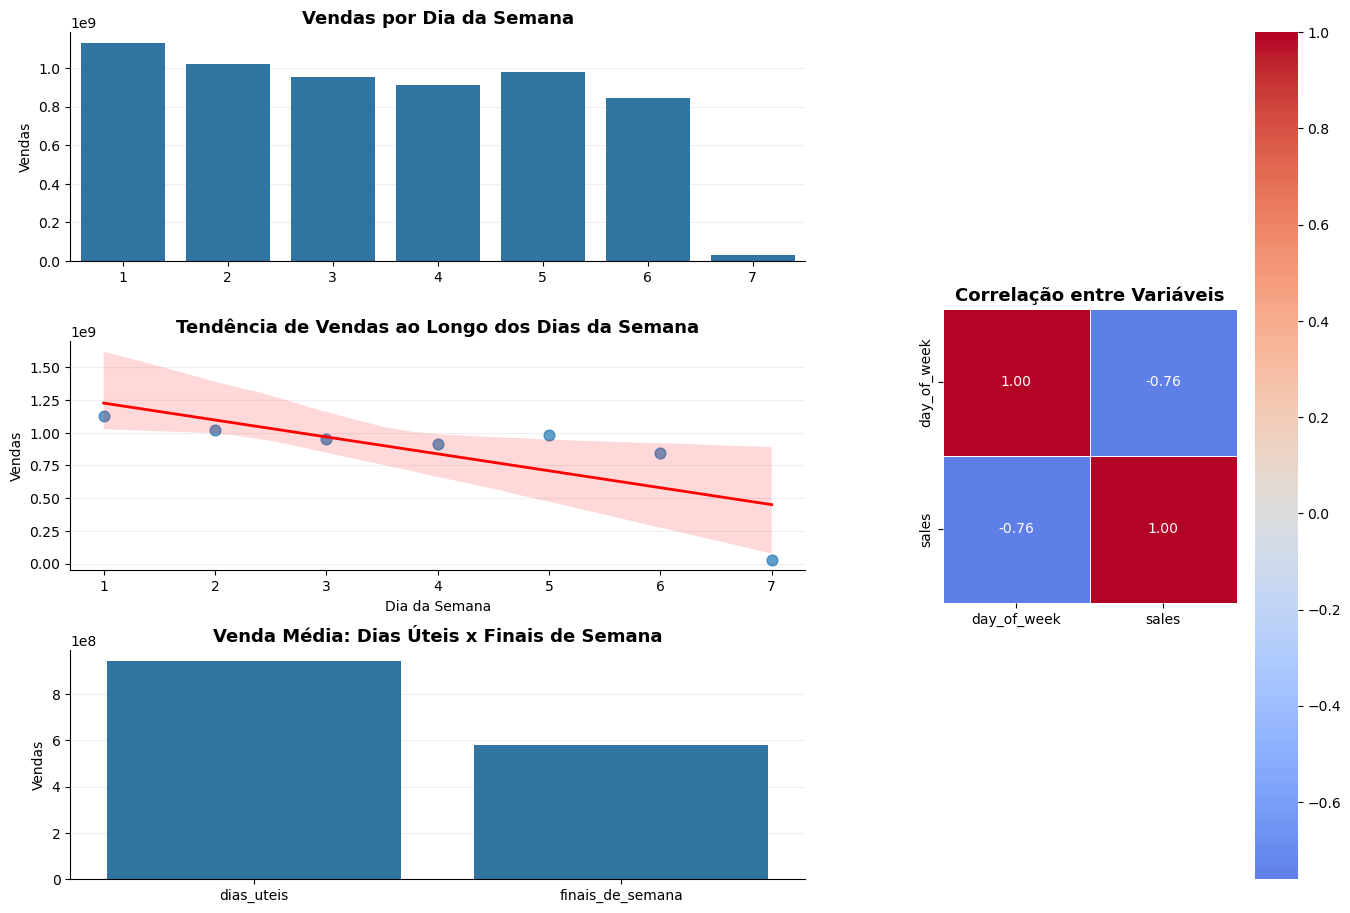

In [41]:
fig = plt.figure(figsize=(16, 11))

gs = fig.add_gridspec(
    3, 2,
    width_ratios=[2, 1],
    height_ratios=[1, 1, 1],
    hspace=0.35,
    wspace=0.25
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[:, 1])

# Preparação dos dados
aux1 = df4[['day_of_week', 'sales']].groupby('day_of_week').sum().reset_index()

# 1. Gráfico de barras
sns.barplot(
    x='day_of_week',
    y='sales',
    data=aux1,
    ax=ax1
)

ax1.set_title('Vendas por Dia da Semana', fontsize=13, weight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Vendas')
ax1.grid(axis='y', alpha=0.2)
ax1.set_axisbelow(True)

# 2. Gráfico de regressão
sns.regplot(
    x='day_of_week',
    y='sales',
    data=aux1,
    ax=ax2,
    scatter_kws={'s': 60, 'alpha': 0.7},
    line_kws={'color': 'red', 'linewidth': 2}
)

ax2.set_title('Tendência de Vendas ao Longo dos Dias da Semana', fontsize=13, weight='bold')
ax2.set_xlabel('Dia da Semana')
ax2.set_ylabel('Vendas')
ax2.grid(axis='y', alpha=0.2)
ax2.set_axisbelow(True)

# 3. Vendas antes e depois do dia 10
aux1['vendas_finais_semana'] = aux1['day_of_week'].apply(lambda x: 'finais_de_semana' if x in [7, 1] else 'dias_uteis')

aux2 = aux1[['vendas_finais_semana', 'sales']].groupby('vendas_finais_semana').mean().reset_index()

sns.barplot(
    x='vendas_finais_semana',
    y='sales',
    data=aux2,
    ax=ax3
)

ax3.set_title('Venda Média: Dias Úteis x Finais de Semana', fontsize=13, weight='bold')
ax3.set_xlabel('')
ax3.set_ylabel('Vendas')
ax3.grid(axis='y', alpha=0.2)
ax3.set_axisbelow(True)

# 4. Heatmap
sns.heatmap(
    aux1[['day_of_week', 'sales']].corr(method='pearson'),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    square=True,
    ax=ax4
)

ax4.set_title('Correlação entre Variáveis', fontsize=13, weight='bold')

# Removendo bordas desnecessárias
for ax in [ax1, ax2, ax3]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.patch.set_facecolor('white')

plt.show()

### **H12.** Lojas deveriam vender menos durante feriados escolares.
#### **FALSO:** Lojas VENDEM MAIS DURANTE FERIADOS ESCOLARES.

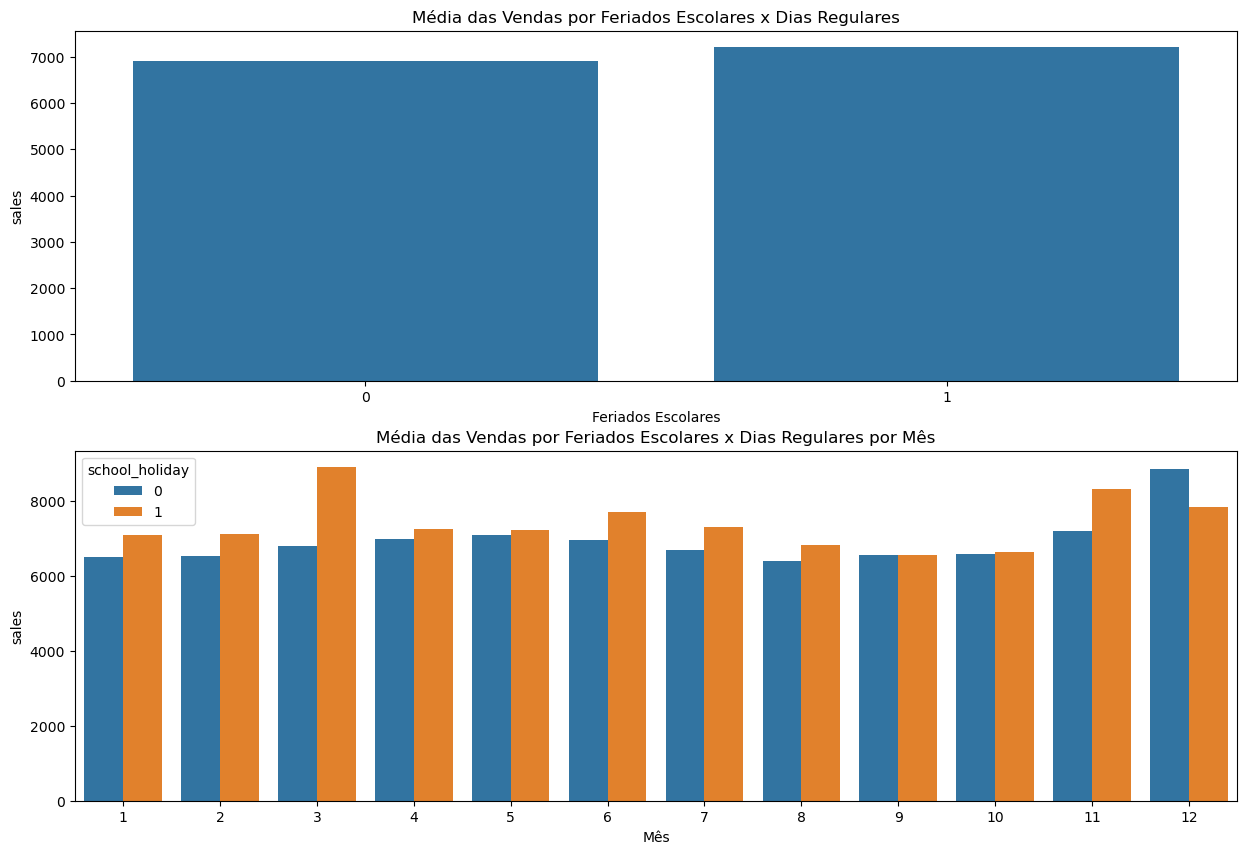

In [42]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(15, 10))

aux1 = df4[['school_holiday', 'sales']].groupby('school_holiday').mean().reset_index()
sns.barplot(x='school_holiday', y='sales', data=aux1, ax=ax[0]);
ax[0].set_title('Média das Vendas por Feriados Escolares x Dias Regulares');
ax[0].set_xlabel('Feriados Escolares');

aux2 = df4[['month', 'school_holiday', 'sales']].groupby(['month', 'school_holiday']).mean().reset_index()
sns.barplot(x='month', y='sales', hue='school_holiday', data=aux2, ax=ax[1]);
ax[1].set_title('Média das Vendas por Feriados Escolares x Dias Regulares por Mês');
ax[1].set_xlabel('Mês');

### 4.2.1. Resumo das Hipóteses

In [43]:
from tabulate import tabulate

In [44]:
tab = [
    ['Hipóteses', 'Conclusão', 'Relevância'],
    ['H1', 'Falsa', 'Baixa'],
    ['H2', 'Falsa', 'Média'],
    ['H3', 'Falsa', 'Média'],
    ['H4', 'Falsa', 'Baixa'],
    ['H5', '-', '-'],
    ['H6', 'Falsa', 'Baixa'],
    ['H7', 'Falsa', 'Média'],
    ['H8', 'Falsa', 'Alta'],
    ['H9', 'Falsa', 'Alta'],
    ['H10', 'Falsa', 'Alta'],
    ['H11', 'Verdadeira', 'Alta'],
    ['H12', 'Falsa', 'Baixa']
]

print(tabulate(tab, headers='firstrow'))

Hipóteses    Conclusão    Relevância
-----------  -----------  ------------
H1           Falsa        Baixa
H2           Falsa        Média
H3           Falsa        Média
H4           Falsa        Baixa
H5           -            -
H6           Falsa        Baixa
H7           Falsa        Média
H8           Falsa        Alta
H9           Falsa        Alta
H10          Falsa        Alta
H11          Verdadeira   Alta
H12          Falsa        Baixa


## 4.3. Análise Multivariada

### 4.3.1. Numerical Attributes

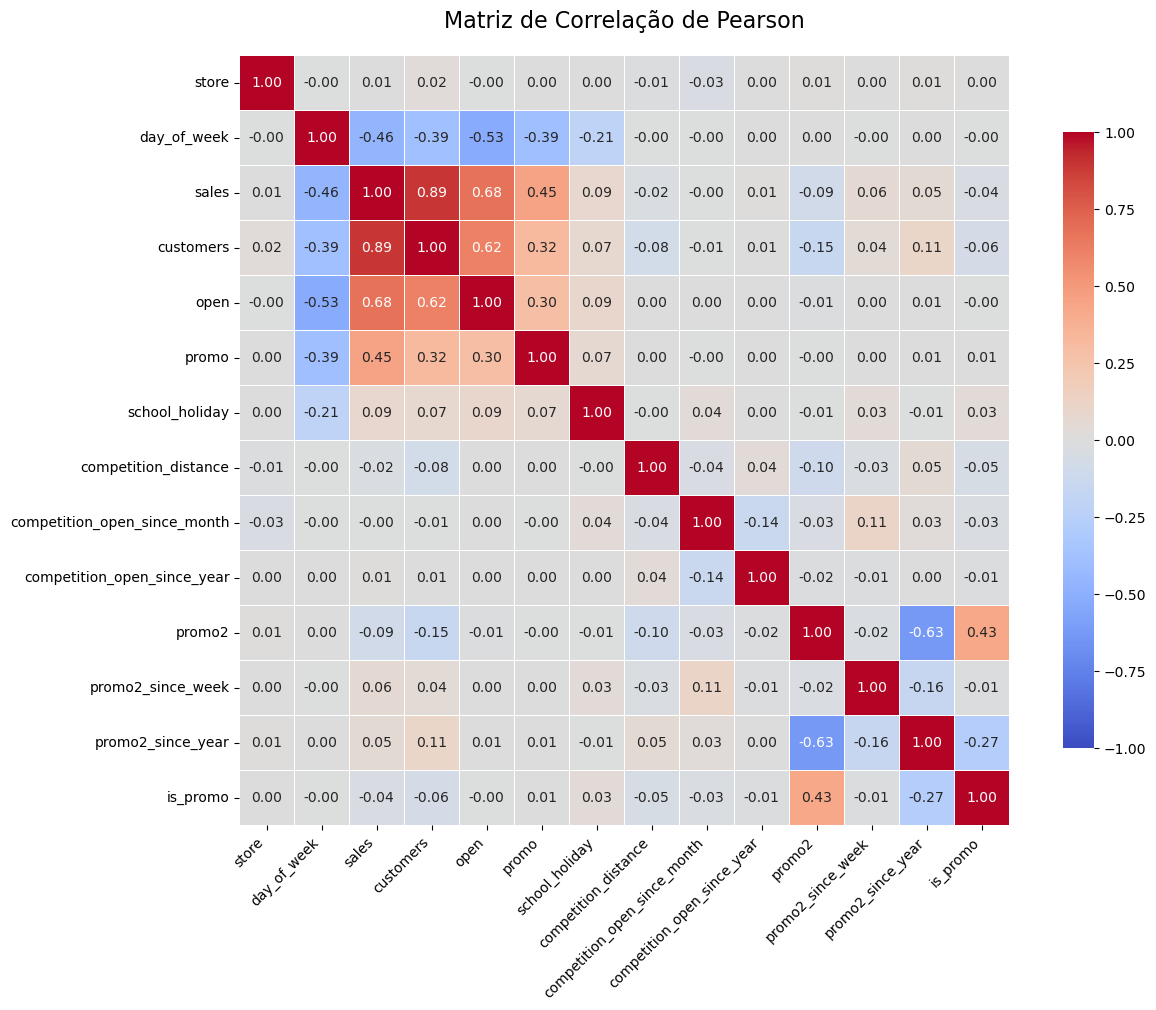

In [45]:
correlation = num_attributes.corr(method='pearson')

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    linecolor='white',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    cbar_kws={'shrink': 0.8}
)

plt.title('Matriz de Correlação de Pearson', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.show()

### 4.3.2. Categorical Attributes

In [46]:
# seleciona somente variáveis categóricas
a = df4.select_dtypes(include='object')

In [47]:
def cramer_v(x, y):
    cm = pd.crosstab(x, y).to_numpy() # matriz de confusão entre duas variáveis categóricas
    n = cm.sum() # total geral de observações
    r, k = cm.shape # r = número de linhas, k = número de colunas
    
    chi2 = stats.chi2_contingency( cm )[0] # teste qui-quadrado de pearson

    # correção de viés
    chi2corr = max(0, chi2 - (k - 1) * (r - 1) / (n - 1) )
    kcorr = k - (k - 1)**2 / (n - 1)
    rcorr = r - (r - 1)**2 / (n - 1)

    return np.sqrt( (chi2corr / n) / (min(kcorr - 1, rcorr - 1)) )

In [48]:
# combinações de todas as variáveis categóricas para a construção da matriz de correlação 
a1 = cramer_v(df4['state_holiday'], df4['state_holiday'])
a2 = cramer_v(df4['state_holiday'], df4['store_type'])
a3 = cramer_v(df4['state_holiday'], df4['assortment'])

a4 = cramer_v(df4['store_type'], df4['state_holiday'])
a5 = cramer_v(df4['store_type'], df4['store_type'])
a6 = cramer_v(df4['store_type'], df4['assortment'])

a7 = cramer_v(df4['assortment'], df4['state_holiday'])
a8 = cramer_v(df4['assortment'], df4['store_type'])
a9 = cramer_v(df4['assortment'], df4['assortment'])

d = pd.DataFrame({
    'state_holiday': [a1, a2, a3],
    'store_type': [a4, a5, a6],
    'assortment': [a7, a8, a9]
})

d = d.set_index(d.columns)

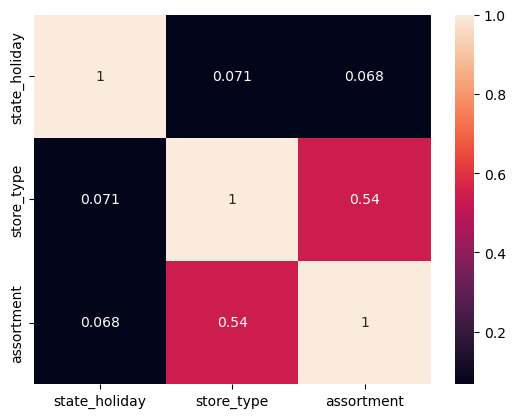

In [49]:
sns.heatmap(d, annot=True);

# 5.0. Passo 05 - PREPARACAO DOS DADOS

In [82]:
df5 = df4.copy()

## 5.1. Normalizacao

## 5.2. Rescaling

In [83]:
rs = RobustScaler()
mms = MinMaxScaler()

# competition_distance
df5['competition_distance'] = rs.fit_transform(df5[['competition_distance']].values)

# competition_time_month
df5['competition_time_month'] = rs.fit_transform(df5[['competition_time_month']].values)

# promo_time_week
df5['promo_time_week'] = mms.fit_transform(df5[['promo_time_week']].values)

# year
df5['year'] = mms.fit_transform(df5[['year']].values)

## 5.3. Transformacao

### 5.3.1. Encoding

In [84]:
# state_holiday - One Hot Encoding
df5 = pd.get_dummies(df5, prefix=['state_holiday'], columns=['state_holiday'], dtype=int)

# store_type - Label Encoding
le = LabelEncoder()
df5['store_type'] = le.fit_transform(df5['store_type'])

# assortment - Ordinal Encoding
assortment_dict = {'basic': 1, 'extra': 2, 'extended': 3}
df5['assortment'] = df5['assortment'].map(assortment_dict)

In [52]:
# month
# day
# week_of_year
# day_of_week